# Smart Sensor Placement — Merged Pipeline

Data loading (Person 1) + Gaussian Process & greedy placement (Person 2).

**What changed from the earlier notebooks**

1. Moisture is now a **30-day average** (June 2023) instead of a single day's reading.
   A single day is dominated by whether it happened to rain at that station, which makes
   neighbouring stations look like they disagree. Averaging removes that noise and leaves
   the underlying spatial pattern.
2. The `n=5` row of the experiment was broken: `n_add = n - 5` meant the greedy loop never
   ran, so "greedy" at 5 sensors was just another random draw. Fixed by seeding greedy with
   2 sensors instead of 5.
3. Physically impossible readings (moisture <= 0) are dropped.

The GP and the placement algorithm are **otherwise unchanged**, so any improvement in the
results comes from the data, not from moving the goalposts.
4. **Fair evaluation** (section 7): missing `evaluate_selection` added, fixed held-out test set per run, mean baseline, ± std in the printout.
5. **Better GP** (sections 10–11): Matern kernel, km distances, elevation input; best one re-runs the placement experiment.
6. **Coarse prior** (section 12): ERA5-Land soil moisture as the starting estimate; stations correct it.
7. **Trustworthy result** (section 13): four months, kernel learned without test stations, sign-test p-values, calibration-aware placement.
8. **Real satellite data** (section 14): NASA SMAP L3 (36 km) as the prior, compared head-to-head with ERA5.
9. **k-means baselines** (section 15): does calibration-aware MI beat simply spreading sensors evenly?
10. **Strict evaluation** (section 16): kernel learned from 2022, so no 2023 reading outside the chosen sensors is ever used. Exports `historical_kernel.json` and `experiment_results.json` for the app.


## 1. Setup

In [1]:
import json
import requests
import time
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import warnings

from sklearn.gaussian_process import GaussianProcessRegressor
from sklearn.gaussian_process.kernels import RBF, WhiteKernel, ConstantKernel
from sklearn.metrics import mean_absolute_error
from sklearn.exceptions import ConvergenceWarning

warnings.filterwarnings("ignore", category=ConvergenceWarning)

STATIONS_URL = "https://wcc.sc.egov.usda.gov/awdbRestApi/services/v1/stations"
DATA_URL     = "https://wcc.sc.egov.usda.gov/awdbRestApi/services/v1/data"

# The time window. Ground data and any future satellite data must use the SAME window.
BEGIN_DATE = "2023-06-01"
END_DATE   = "2023-06-30"

# SMS = soil moisture, -2 = two inches deep (~5 cm, the surface layer the satellite sees),
# 1 = sensor number 1 at that depth.
ELEMENT = "SMS:-2:1"

print("ready")

ready


## 2. Get the station list

USDA's station endpoint returns every station in every network (~4400). We keep only SCAN —
the Soil Climate Analysis Network — which is the one that measures soil moisture.

In [2]:
r = requests.get(STATIONS_URL, params={"activeOnly": "true"}, timeout=60)
print("status:", r.status_code)

st = pd.DataFrame(r.json())
cols = ["stationTriplet", "name", "stateCode", "latitude", "longitude"]
if "elevation" in st.columns:
    cols.append("elevation")          # NEW: kept for section 10 (feet)
scan = st[st.networkCode == "SCAN"][cols].reset_index(drop=True)

print("SCAN stations:", len(scan))
scan.head()

status: 200
SCAN stations: 210


,stationTriplet,name,stateCode,latitude,longitude,elevation
0,2057:AL:SCAN,AAMU-JTG,AL,34.78534,-86.55906,800.0
1,2092:KS:SCAN,Abrams,KS,37.13130,-97.08590,1190.0
2,2015:NM:SCAN,Adams Ranch #1,NM,34.25294,-105.41973,6170.0
3,2235:CA:SCAN,Adobe,CA,37.97787,-118.68626,6500.0
4,2237:CA:SCAN,Alabama Hills,CA,36.56295,-118.13562,5240.0


## 3. Cut to the continental US

Alaska, Hawaii and Puerto Rico sit thousands of km from everything else. A Gaussian Process
learns "nearby places are similar" — isolated islands have no neighbours, so they only drag
the fitted length-scale around. We drop them with a bounding box.

In [3]:
mainland = scan[
    (scan.latitude  > 25) & (scan.latitude  < 50) &
    (scan.longitude > -125) & (scan.longitude < -66)
].reset_index(drop=True)

print("mainland stations:", len(mainland))

mainland stations: 193


## 4. Fetch moisture and average it

All station IDs go in **one** request (comma-joined) rather than 194 separate calls.

Stations with no sensor at this exact depth are simply absent from the response — that is
normal, not an error. We keep whatever comes back.

In [4]:
all_ids = list(mainland.stationTriplet)

params = {
    "stationTriplets": ",".join(all_ids),
    "elements": ELEMENT,
    "duration": "DAILY",
    "beginDate": BEGIN_DATE,
    "endDate": END_DATE,
}

r = requests.get(DATA_URL, params=params, timeout=300)
print("status:", r.status_code)

out = r.json()
print("stations with data:", len(out), "out of", len(all_ids))

status: 200
stations with data: 169 out of 193


In [5]:
rows = []

for s in out:
    series = s.get("data", [])
    if not series:
        continue
    values = [v["value"] for v in series[0]["values"] if v.get("value") is not None]
    if not values:
        continue
    rows.append({
        "stationTriplet": s["stationTriplet"],
        "moisture": sum(values) / len(values),   # 30-day average
        "n_days": len(values),
    })

readings = pd.DataFrame(rows)
print("stations with a usable average:", len(readings))
print("days per station: min", readings.n_days.min(), "max", readings.n_days.max())
readings.head()

stations with a usable average: 169
days per station: min 9 max 30


,stationTriplet,moisture,n_days
0,2057:AL:SCAN,24.023333,30
1,2092:KS:SCAN,14.326667,30
2,2015:NM:SCAN,10.730000,30
3,2172:NM:SCAN,14.046667,30
4,2138:UT:SCAN,6.426667,30


### Join locations to values

`merge` matches **by station ID**, not by row position. That matters: the two tables are
different lengths, so pairing them by position would silently attach one station's moisture
to another station's coordinates.

In [6]:
sensors = mainland.merge(readings, on="stationTriplet", how="inner")

# A 2-inch sensor reading 0% for a whole month is a dead sensor, not dry soil.
before = len(sensors)
sensors = sensors[sensors.moisture > 0].reset_index(drop=True)
print("dropped", before - len(sensors), "station(s) with impossible readings")

print("FINAL DATASET:", len(sensors), "stations")
print(sensors.moisture.describe())

dropped 0 station(s) with impossible readings
FINAL DATASET: 169 stations
count    169.000000
mean      15.847059
std        9.532543
min        0.213333
25%        8.136667
50%       14.800000
75%       21.626667
max       47.800000
Name: moisture, dtype: float64


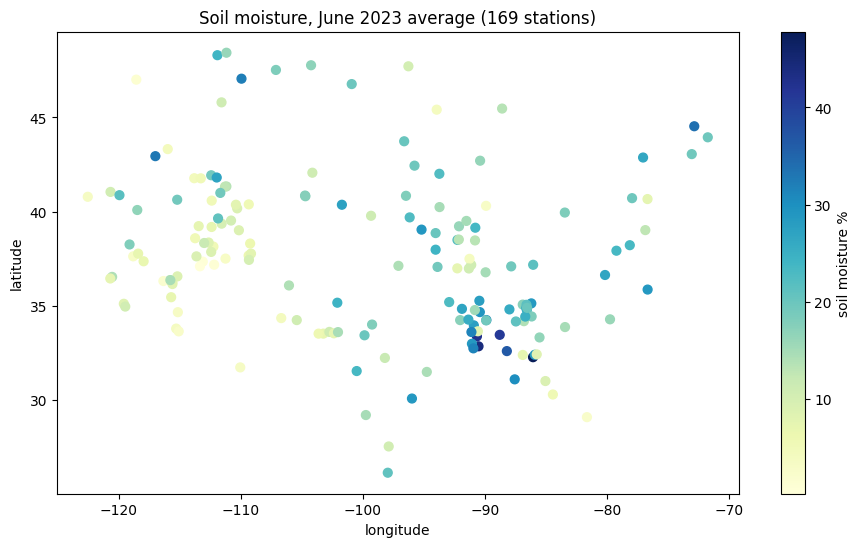

In [7]:
plt.figure(figsize=(11, 6))
sc = plt.scatter(sensors.longitude, sensors.latitude, c=sensors.moisture,
                 cmap="YlGnBu", s=40)
plt.colorbar(sc, label="soil moisture %")
plt.xlabel("longitude"); plt.ylabel("latitude")
plt.title(f"Soil moisture, June 2023 average ({len(sensors)} stations)")
plt.show()

## 5. The Gaussian Process

The GP returns two things for any location: a predicted value, and a standard deviation —
how unsure it is. The second output is the whole reason we use a GP instead of ordinary
interpolation.

**Kernel:** `Constant * RBF + WhiteKernel`
- RBF encodes "nearby places are similar", and its `length_scale` is *how* near.
- WhiteKernel is measurement noise — it lets the model accept that two adjacent stations
  can genuinely disagree without forcing the surface to wiggle through every point.

In [8]:
# Learn the kernel ONCE from all stations
X_full = sensors[["longitude", "latitude"]].values
y_full = sensors["moisture"].values

_probe = GaussianProcessRegressor(
    kernel=ConstantKernel(1.0) * RBF(length_scale=5.0) + WhiteKernel(noise_level=0.1),
    n_restarts_optimizer=5, normalize_y=False,
)
_probe.fit(X_full, (y_full - y_full.mean()) / y_full.std())
FIXED_KERNEL = _probe.kernel_
print("kernel learned once from all stations:", FIXED_KERNEL)


def fit_gp(X, y):
    """Fit using the fixed kernel. optimizer=None stops it re-learning from too few points."""
    y_mean = y.mean()
    y_std  = y.std() if y.std() > 0 else 1.0

    gp = GaussianProcessRegressor(kernel=FIXED_KERNEL, optimizer=None, normalize_y=False)
    gp.fit(X, (y - y_mean) / y_std)
    return gp, y_mean, y_std


gp, y_mean, y_std = fit_gp(X_full, y_full)
pred_scaled, _ = gp.predict(X_full[0].reshape(1, -1), return_std=True)
print(f"predicted {pred_scaled[0]*y_std + y_mean:.2f}  |  actual {y_full[0]:.2f}")

kernel learned once from all stations: 0.613**2 * RBF(length_scale=3.59) + WhiteKernel(noise_level=0.531)
predicted 22.13  |  actual 24.02


### The confidence map

Predict over a grid covering the whole region. Dark = the model has little idea what is
happening there. Those are the places a new sensor would teach us the most.

prediction  4.3 to 30.6 %
uncertainty 7.1 to 9.0 %


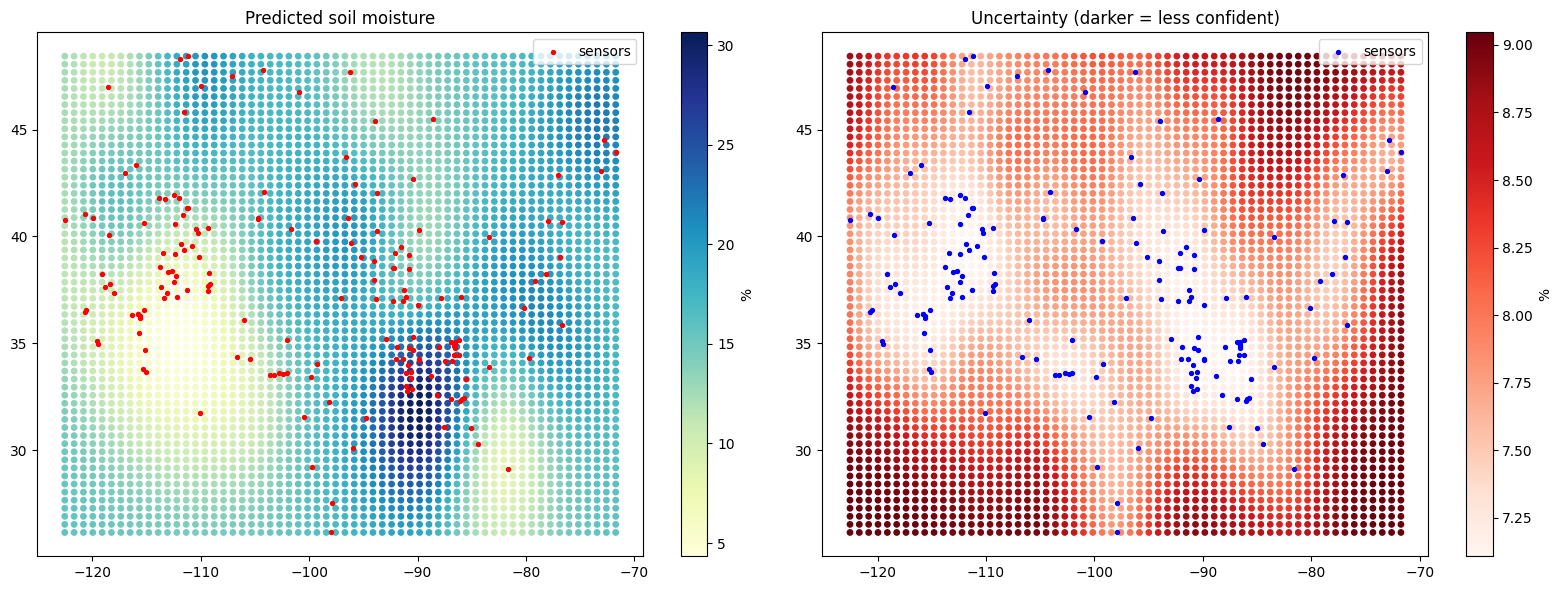

In [9]:
grid_lon = np.linspace(sensors.longitude.min(), sensors.longitude.max(), 60)
grid_lat = np.linspace(sensors.latitude.min(),  sensors.latitude.max(),  60)
mesh_lon, mesh_lat = np.meshgrid(grid_lon, grid_lat)
grid_points = np.column_stack([mesh_lon.ravel(), mesh_lat.ravel()])

pred_scaled, std_scaled = gp.predict(grid_points, return_std=True)
pred = pred_scaled * y_std + y_mean
std  = std_scaled  * y_std

print(f"prediction  {pred.min():.1f} to {pred.max():.1f} %")
print(f"uncertainty {std.min():.1f} to {std.max():.1f} %")

fig, axes = plt.subplots(1, 2, figsize=(16, 6))

c1 = axes[0].scatter(grid_points[:,0], grid_points[:,1], c=pred, cmap="YlGnBu", s=15)
axes[0].scatter(sensors.longitude, sensors.latitude, c="red", s=8, label="sensors")
axes[0].set_title("Predicted soil moisture"); axes[0].legend()
plt.colorbar(c1, ax=axes[0], label="%")

c2 = axes[1].scatter(grid_points[:,0], grid_points[:,1], c=std, cmap="Reds", s=15)
axes[1].scatter(sensors.longitude, sensors.latitude, c="blue", s=8, label="sensors")
axes[1].set_title("Uncertainty (darker = less confident)"); axes[1].legend()
plt.colorbar(c2, ax=axes[1], label="%")

plt.tight_layout(); plt.show()

## 6. Greedy placement

1. Fit the GP on the sensors we have.
2. Ask it how unsure it is at every candidate location.
3. Put the next sensor at the least-confident one.
4. Repeat.

This is the **entropy (variance) criterion**. Note for the report: Krause, Singh & Guestrin
(2008) show this criterion tends to push sensors to the *edges* of the region, because
boundary points have fewest neighbours and so always look uncertain. A sensor on the border
only informs the area on one side of it, so some of its coverage is wasted. Watch which
stations get picked below — if they are mostly edge stations, we are seeing that effect.

In [10]:
JITTER = 1e-8

def _post_var(Xq, Xs):
    """How unsure the GP is at Xq, after observing the stations in Xs."""
    if len(Xs) == 0:
        return FIXED_KERNEL.diag(Xq)
    Kss = FIXED_KERNEL(Xs) + JITTER*np.eye(len(Xs))
    Kqs = FIXED_KERNEL(Xq, Xs)
    v = np.linalg.solve(Kss, Kqs.T)
    return np.maximum(FIXED_KERNEL.diag(Xq) - np.sum(Kqs*v.T, axis=1), 1e-12)


def _var_given_other_candidates(Xc):
    """For each candidate, how unsure we'd be there if we knew every OTHER
    unplaced location. Uses the identity var(i | rest) = 1 / (K^-1)[i,i]."""
    K = FIXED_KERNEL(Xc) + JITTER*np.eye(len(Xc))
    return np.maximum(1.0/np.diag(np.linalg.inv(K)), 1e-12)


def greedy_placement(sensors_df, n_start=2, n_add=10, seed=42, criterion="mutual_info", pool=None):
    rng = np.random.default_rng(seed)
    # NEW: only pick from 'pool' (stations not in the test set). None = all stations.
    if pool is None:
        pool = list(range(len(sensors_df)))
    idx = np.array(pool); rng.shuffle(idx)
    known, cand = list(idx[:n_start]), list(idx[n_start:])
    X_all = sensors_df[["longitude", "latitude"]].values
    order = []

    for _ in range(n_add):
        if not cand: break
        Xc = X_all[cand]
        var_A = _post_var(Xc, X_all[known])          # how unsure we are here now

        if criterion == "entropy":
            score = var_A                             # old: just pick the least known
        else:
            # new: how much does knowing here help with everywhere ELSE?
            score = var_A / _var_given_other_candidates(Xc)

        best = int(np.argmax(score)); chosen = cand[best]
        order.append(chosen); known.append(chosen); cand.pop(best)

    return known, order


for crit in ["entropy", "mutual_info"]:
    _, o = greedy_placement(sensors, n_start=2, n_add=8, seed=42, criterion=crit)
    print(f"\n--- {crit} ---")
    for rank, i in enumerate(o, 1):
        r = sensors.iloc[i]
        print(f"  {rank}. {r['name']} ({r['stateCode']})  "
              f"lat {r['latitude']:.2f}, lon {r['longitude']:.2f}")


--- entropy ---
  1. Ash Valley (CA)  lat 41.05, lon -120.69
  2. Sidney (MT)  lat 47.77, lon -104.25
  3. Hubbard Brook (NH)  lat 43.95, lon -71.73
  4. Walnut Gulch #1 (AZ)  lat 31.74, lon -110.05
  5. Weslaco (TX)  lat 26.16, lon -97.96
  6. Wabeno #1 (WI)  lat 45.47, lon -88.59
  7. Phillipsburg (KS)  lat 39.79, lon -99.33
  8. Tidewater #1 (NC)  lat 35.87, lon -76.66

--- mutual_info ---
  1. Ephraim (UT)  lat 39.37, lon -111.58
  2. Death Valley Jct (CA)  lat 36.33, lon -116.35
  3. Levelland (TX)  lat 33.55, lon -102.37
  4. Powell Gardens (MO)  lat 38.87, lon -94.04
  5. N Piedmont Arec (VA)  lat 38.23, lon -78.12
  6. Bodie Hills (CA)  lat 38.26, lon -119.13
  7. Park Valley (UT)  lat 41.77, lon -113.29
  8. North Issaquena (MS)  lat 33.00, lon -91.06


## 7. The experiment

Pick N stations, fit the GP on those, predict a **fixed held-out test set**, measure the error.

**Fixes in this version:**
1. `evaluate_selection` is now defined (it was missing, so "Run all" crashed).
2. Every run first sets aside 40 test stations. All methods pick only from the other stations,
   and all are scored on the *same* 40. Before, each method was scored on whatever it didn't pick,
   so greedy got to remove the hardest (remote) stations from its own test set.
3. Added a **mean baseline**: predict the average of the chosen stations everywhere.
   If the GP doesn't beat this, the GP isn't adding anything.
4. The printout now shows mean ± std across runs.

Greedy still seeds with 2 random stations, so at N=5 it places 3 using the algorithm.

In [11]:
def evaluate_selection(sensors_df, chosen, test_idx):
    """Fit GP on the chosen stations, predict the test stations, return MAE."""
    X = sensors_df[["longitude", "latitude"]].values
    y = sensors_df["moisture"].values
    gp, m, s = fit_gp(X[chosen], y[chosen])
    p, _ = gp.predict(X[test_idx], return_std=True)
    p = p * s + m
    return mean_absolute_error(y[test_idx], p)


def evaluate_mean_baseline(sensors_df, chosen, test_idx):
    """Predict the plain average of the chosen stations at every test station."""
    y = sensors_df["moisture"].values
    guess = y[chosen].mean()
    total = 0.0
    for i in range(len(test_idx)):
        total = total + abs(y[test_idx[i]] - guess)
    return total / len(test_idx)

In [12]:
N_TEST = 40   # stations held out for scoring in every run

def run_experiment(sensors_df, sensor_counts=(5,10,20,30,50,80,100), n_runs=20, n_start=2):
    methods = ["mean", "random", "entropy", "mutual_info"]
    results = {}
    for m in methods:
        results[m] = {}

    for n in sensor_counts:
        errs = {}
        for m in methods:
            errs[m] = []

        for run in range(n_runs):
            rng = np.random.default_rng(run)
            order = rng.permutation(len(sensors_df))
            test_idx = list(order[:N_TEST])     # same test set for every method this run
            pool = list(order[N_TEST:])         # methods may only pick from here

            rand_pick = list(rng.choice(pool, n, replace=False))
            errs["random"].append(evaluate_selection(sensors_df, rand_pick, test_idx))
            errs["mean"].append(evaluate_mean_baseline(sensors_df, rand_pick, test_idx))

            for crit in ["entropy", "mutual_info"]:
                k, _ = greedy_placement(sensors_df, n_start=n_start, n_add=n-n_start,
                                        seed=run, criterion=crit, pool=pool)
                errs[crit].append(evaluate_selection(sensors_df, k, test_idx))

        for m in methods:
            results[m][n] = (np.mean(errs[m]), np.std(errs[m]))

        best = min(methods, key=lambda m: results[m][n][0])
        line = f"n={n:3d}  "
        for m in methods:
            line = line + f"{m} {results[m][n][0]:.2f}±{results[m][n][1]:.2f}  "
        print(line + f"-> best: {best}")

    return results


results = run_experiment(sensors)

n=  5  mean 9.04±1.42  random 8.45±1.57  entropy 8.06±1.05  mutual_info 7.72±0.91  -> best: mutual_info
n= 10  mean 8.23±0.81  random 7.39±0.97  entropy 7.34±0.95  mutual_info 7.20±0.89  -> best: mutual_info
n= 20  mean 8.35±0.83  random 7.05±1.15  entropy 6.80±0.96  mutual_info 6.72±0.83  -> best: mutual_info
n= 30  mean 8.25±0.71  random 6.60±0.75  entropy 6.60±0.92  mutual_info 6.40±0.78  -> best: mutual_info
n= 50  mean 8.10±0.65  random 6.20±0.77  entropy 6.25±0.81  mutual_info 6.28±0.84  -> best: random
n= 80  mean 8.08±0.73  random 6.09±0.67  entropy 5.95±0.76  mutual_info 6.05±0.80  -> best: entropy
n=100  mean 8.10±0.68  random 5.95±0.67  entropy 5.83±0.76  mutual_info 6.00±0.78  -> best: entropy


## 8. The graph

Section 5 of the proposal: *"That single graph is the core result of the project."*

The shaded bands are one standard deviation across runs. **If the bands overlap heavily,
the difference is not yet meaningful** — that is an honest reading, and worth stating in the
report rather than hiding.

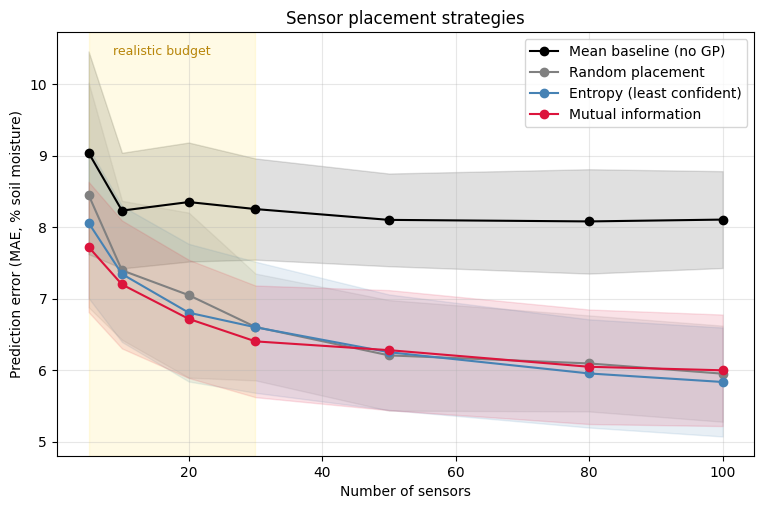

In [13]:
counts = sorted(results["random"])
styles = {"mean": ("black", "Mean baseline (no GP)"),
          "random": ("gray", "Random placement"),
          "entropy": ("steelblue", "Entropy (least confident)"),
          "mutual_info": ("crimson", "Mutual information")}

plt.figure(figsize=(9, 5.5))
for m, (colour, label) in styles.items():
    mu = np.array([results[m][n][0] for n in counts])
    sd = np.array([results[m][n][1] for n in counts])
    plt.plot(counts, mu, marker="o", color=colour, label=label)
    plt.fill_between(counts, mu-sd, mu+sd, color=colour, alpha=0.12)

plt.axvspan(5, 30, color="gold", alpha=0.10)
plt.text(16, plt.ylim()[1]*0.97, "realistic budget", ha="center", fontsize=9, color="darkgoldenrod")

plt.xlabel("Number of sensors")
plt.ylabel("Prediction error (MAE, % soil moisture)")
plt.title("Sensor placement strategies")
plt.legend(); plt.grid(alpha=0.3)
plt.show()

## 10. Making the GP itself better

The placement results are limited by the model: the learned kernel says measurement noise is
*bigger* than the spatial signal, so the GP can only explain part of the variation. Placement can't
fix that. Here we try three changes, one at a time, and keep whichever predicts best:

1. **Matern kernel instead of RBF.** RBF assumes the surface is perfectly smooth. Soil moisture
   changes abruptly (soil type, irrigation, terrain), and Matern (nu=1.5) allows rougher surfaces.
2. **Distance in km instead of degrees.** One degree of longitude is ~100 km in Texas but ~75 km in
   Montana. Treating degrees as flat x/y stretches the map unevenly.
3. **Elevation as a third input.** Mountains vs plains matters a lot for soil moisture, and two
   nearby stations at very different heights shouldn't be treated as "close". ARD gives each input
   its own length-scale, so the model learns how much elevation matters.

Every setup is scored the same way as section 7: same random splits, same 40 test stations.

In [14]:
from sklearn.gaussian_process.kernels import Matern

def make_features(df, setup):
    """Build the GP input matrix for one setup."""
    lon = df["longitude"].values
    lat = df["latitude"].values
    n = len(df)

    if setup["coords"] == "km":
        x = np.zeros(n)
        y = np.zeros(n)
        for i in range(n):
            x[i] = lon[i] * 111.32 * np.cos(np.radians(lat[i])) / 1000.0   # thousands of km
            y[i] = lat[i] * 110.57 / 1000.0
        cols = [x, y]
    else:
        cols = [lon, lat]                                                  # raw degrees

    if setup["elevation"]:
        elev_m = df["elevation"].values * 0.3048                           # feet -> metres
        cols.append(elev_m / 1000.0)                                       # km

    return np.column_stack(cols)


def learn_kernel(X, y, setup, restarts=5):
    """Learn kernel hyperparameters once, like FIXED_KERNEL in section 5."""
    d = X.shape[1]
    start_ls = 5.0 if setup["coords"] == "deg" else 1.0
    if setup["ard"]:
        ls = np.full(d, start_ls)
    else:
        ls = start_ls

    if setup["kernel"] == "matern":
        base = Matern(length_scale=ls, nu=1.5)
    else:
        base = RBF(length_scale=ls)

    k = ConstantKernel(1.0) * base + WhiteKernel(noise_level=0.1)
    gp = GaussianProcessRegressor(kernel=k, n_restarts_optimizer=restarts, normalize_y=False)
    gp.fit(X, (y - y.mean()) / y.std())
    return gp.kernel_


# Same functions as sections 5-7, but the kernel and inputs are passed in
def fit_gp_k(kernel, X, y):
    y_mean = y.mean()
    y_std = y.std() if y.std() > 0 else 1.0
    gp = GaussianProcessRegressor(kernel=kernel, optimizer=None, normalize_y=False)
    gp.fit(X, (y - y_mean) / y_std)
    return gp, y_mean, y_std


def evaluate_k(kernel, X, y, chosen, test_idx):
    gp, m, s = fit_gp_k(kernel, X[chosen], y[chosen])
    p = gp.predict(X[test_idx]) * s + m
    return mean_absolute_error(y[test_idx], p)


def post_var_k(kernel, Xq, Xs):
    Kss = kernel(Xs) + JITTER * np.eye(len(Xs))
    Kqs = kernel(Xq, Xs)
    v = np.linalg.solve(Kss, Kqs.T)
    return np.maximum(kernel.diag(Xq) - np.sum(Kqs * v.T, axis=1), 1e-12)


def var_rest_k(kernel, Xc):
    K = kernel(Xc) + JITTER * np.eye(len(Xc))
    return np.maximum(1.0 / np.diag(np.linalg.inv(K)), 1e-12)


def greedy_k(kernel, X_all, pool, n_start, n_add, seed, criterion):
    rng = np.random.default_rng(seed)
    idx = np.array(pool); rng.shuffle(idx)
    known = list(idx[:n_start])
    cand = list(idx[n_start:])
    for step in range(n_add):
        if len(cand) == 0:
            break
        Xc = X_all[cand]
        var_A = post_var_k(kernel, Xc, X_all[known])
        if criterion == "entropy":
            score = var_A
        else:
            score = var_A / var_rest_k(kernel, Xc)
        best = int(np.argmax(score))
        known.append(cand[best])
        cand.pop(best)
    return known

print("ready")

ready


In [15]:
SETUPS = [
    {"name": "current: RBF, degrees",          "kernel": "rbf",    "coords": "deg", "elevation": False, "ard": False},
    {"name": "Matern, degrees",                "kernel": "matern", "coords": "deg", "elevation": False, "ard": False},
    {"name": "Matern, km",                     "kernel": "matern", "coords": "km",  "elevation": False, "ard": False},
    {"name": "Matern, km + elevation (ARD)",   "kernel": "matern", "coords": "km",  "elevation": True,  "ard": True},
]

# Skip the elevation setup if the station list didn't include elevation
has_elev = "elevation" in sensors.columns and sensors["elevation"].notna().all()
if not has_elev:
    print("No elevation in station data - skipping the elevation setup")
    SETUPS = [s for s in SETUPS if not s["elevation"]]

y_all = sensors["moisture"].values
ABL_RUNS = 50
ABL_COUNTS = [10, 30, len(sensors) - N_TEST]   # last = every station that isn't in the test set

for setup in SETUPS:
    X = make_features(sensors, setup)
    if setup["name"].startswith("current"):
        kernel = FIXED_KERNEL                     # exactly what sections 5-8 used
    else:
        kernel = learn_kernel(X, y_all, setup)
    setup["X"] = X
    setup["kernel_fit"] = kernel

    line = f"{setup['name']:32s}"
    for n in ABL_COUNTS:
        errs = []
        for run in range(ABL_RUNS):
            rng = np.random.default_rng(run)
            order = rng.permutation(len(sensors))
            test_idx = list(order[:N_TEST])
            pool = list(order[N_TEST:])
            pick = list(rng.choice(pool, n, replace=False))
            errs.append(evaluate_k(kernel, X, y_all, pick, test_idx))
        setup[f"mae_{n}"] = np.mean(errs)
        line = line + f"  n={n}: {np.mean(errs):.2f}"
    print(line)
    print(f"{'':32s}  kernel: {kernel}")

BEST = min(SETUPS, key=lambda s: s["mae_30"])
print("\nbest setup (lowest error at 30 sensors):", BEST["name"])

current: RBF, degrees             n=10: 7.16  n=30: 6.54  n=129: 5.77
                                  kernel: 0.613**2 * RBF(length_scale=3.59) + WhiteKernel(noise_level=0.531)
Matern, degrees                   n=10: 7.09  n=30: 6.46  n=129: 5.74
                                  kernel: 0.628**2 * Matern(length_scale=4.76, nu=1.5) + WhiteKernel(noise_level=0.522)
Matern, km                        n=10: 7.20  n=30: 6.54  n=129: 5.82
                                  kernel: 0.611**2 * Matern(length_scale=0.417, nu=1.5) + WhiteKernel(noise_level=0.531)
Matern, km + elevation (ARD)      n=10: 7.17  n=30: 6.54  n=129: 5.86
                                  kernel: 0.607**2 * Matern(length_scale=[0.544, 0.308, 4.8e+04], nu=1.5) + WhiteKernel(noise_level=0.525)

best setup (lowest error at 30 sensors): Matern, degrees


### How to read the kernel lines
`WhiteKernel(noise_level=...)` is the share of variation the model calls noise. The bigger part
before it (`constant**2 * Matern/RBF`) is the spatial signal. If a change makes the noise level
drop, the model is explaining more of the data — which also gives placement more to work with.

## 11. Placement experiment again, with the best GP

Same paired comparison as before (50 runs, same test set for every method within a run), now using
the best setup from section 10.

setup: Matern, degrees 

n=  5  random 8.13  entropy 7.90  MI 7.59  |  MI won 28/50  |  worst: random 12.22, MI 9.97
n= 10  random 7.09  entropy 7.22  MI 7.00  |  MI won 28/50  |  worst: random 8.91, MI 9.22
n= 20  random 6.59  entropy 6.50  MI 6.55  |  MI won 23/50  |  worst: random 9.54, MI 8.61
n= 30  random 6.46  entropy 6.30  MI 6.25  |  MI won 31/50  |  worst: random 8.18, MI 7.95
n= 50  random 6.12  entropy 6.05  MI 6.08  |  MI won 28/50  |  worst: random 7.44, MI 7.82
n= 80  random 5.88  entropy 5.79  MI 5.95  |  MI won 20/50  |  worst: random 7.29, MI 7.75
n=100  random 5.81  entropy 5.73  MI 5.83  |  MI won 24/50  |  worst: random 7.32, MI 7.47


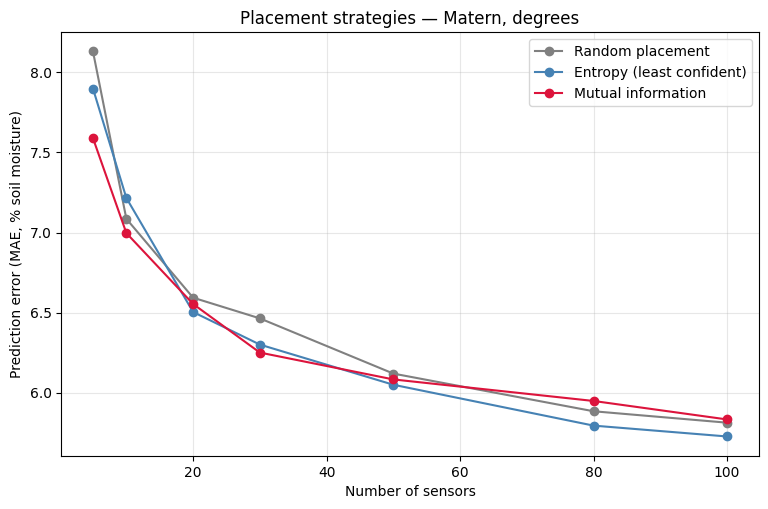

In [16]:
kernel = BEST["kernel_fit"]
X = BEST["X"]
counts = [5, 10, 20, 30, 50, 80, 100]
methods = ["random", "entropy", "mutual_info"]
summary = {}
for m in methods:
    summary[m] = []

print("setup:", BEST["name"], "\n")
for n in counts:
    errs = {}
    for m in methods:
        errs[m] = []
    wins = 0

    for run in range(50):
        rng = np.random.default_rng(run)
        order = rng.permutation(len(sensors))
        test_idx = list(order[:N_TEST])
        pool = list(order[N_TEST:])

        pick = list(rng.choice(pool, n, replace=False))
        errs["random"].append(evaluate_k(kernel, X, y_all, pick, test_idx))
        for crit in ["entropy", "mutual_info"]:
            k = greedy_k(kernel, X, pool, 2, n - 2, run, crit)
            errs[crit].append(evaluate_k(kernel, X, y_all, k, test_idx))

        if errs["mutual_info"][-1] < errs["random"][-1]:
            wins = wins + 1

    for m in methods:
        summary[m].append(np.mean(errs[m]))

    print(f"n={n:3d}  random {np.mean(errs['random']):.2f}  entropy {np.mean(errs['entropy']):.2f}  "
          f"MI {np.mean(errs['mutual_info']):.2f}  |  MI won {wins}/50  |  "
          f"worst: random {max(errs['random']):.2f}, MI {max(errs['mutual_info']):.2f}")

plt.figure(figsize=(9, 5.5))
plt.plot(counts, summary["random"], marker="o", color="gray", label="Random placement")
plt.plot(counts, summary["entropy"], marker="o", color="steelblue", label="Entropy (least confident)")
plt.plot(counts, summary["mutual_info"], marker="o", color="crimson", label="Mutual information")
plt.xlabel("Number of sensors")
plt.ylabel("Prediction error (MAE, % soil moisture)")
plt.title(f"Placement strategies — {BEST['name']}")
plt.legend(); plt.grid(alpha=0.3)
plt.show()

## 12. Adding a coarse gridded prior (the "satellite" part of the proposal)

Section 10 showed location and elevation can't explain most of the variation — more than half is
still "noise". The proposal's idea is to start from a wide-area estimate and let the ground sensors
**correct** it, instead of predicting from nothing.

**Prior source:** ERA5-Land soil moisture (0–7 cm, ~9 km grid), from the free Open-Meteo archive
API (no login). ERA5-Land is a reanalysis — a land-surface model driven by observed weather — rather
than a raw satellite retrieval, so in the report call it a *coarse gridded estimate* standing in for
satellite data. Same window as the ground data: June 2023, averaged over the month.

**Four ways to predict, all scored the same way as before:**
| name | what it does |
|---|---|
| `no_prior` | GP on station readings only (the section 10 winner: Matern, degrees) |
| `prior_only` | just the ERA5 value — no stations used at all. "How good is the wide-but-inaccurate source alone?" |
| `prior+GP` | GP learns the *error* of the prior (station − ERA5) and adds it back |
| `calibrated prior+GP` | first fit `station ≈ a + b·ERA5` on the chosen stations, then GP on what's left |

  fetched 25/169
  fetched 50/169
  fetched 75/169
  fetched 100/169
  fetched 125/169
  fetched 150/169
  fetched 169/169

stations with an ERA5 value: 169 of 169
correlation station vs ERA5: 0.53
mean station 15.8%   mean ERA5 22.5%


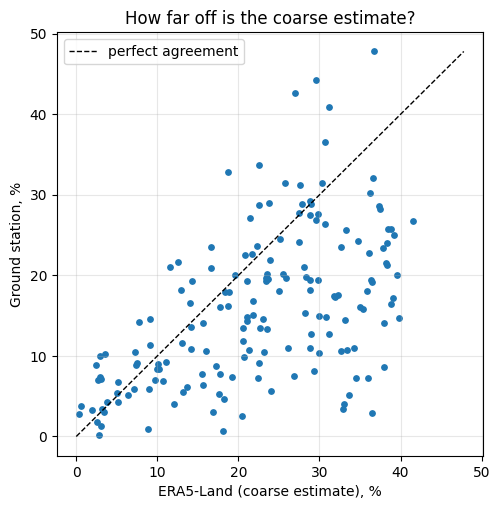

In [17]:
OM_URL = "https://archive-api.open-meteo.com/v1/archive"

def fetch_era5_month(lats, lons, batch=25, begin=None, end=None):
    """Monthly-mean ERA5-Land soil moisture (%), one value per location. NaN if unavailable."""
    if begin is None: begin = BEGIN_DATE
    if end is None: end = END_DATE
    out = []
    for start in range(0, len(lats), batch):
        la = lats[start:start + batch]
        lo = lons[start:start + batch]
        params = {
            "latitude": ",".join(f"{v:.4f}" for v in la),
            "longitude": ",".join(f"{v:.4f}" for v in lo),
            "start_date": begin,
            "end_date": end,
            "hourly": "soil_moisture_0_to_7cm",
            "models": "era5_land",
        }
        for attempt in range(5):
            r = requests.get(OM_URL, params=params, timeout=120)
            if r.status_code == 429:                 # rate limited - wait and retry
                print("  rate limited, waiting 60 s...")
                time.sleep(60)
                continue
            if r.status_code == 400 and "models" in params:
                params.pop("models")                 # fall back to Open-Meteo's default model
                continue
            break
        r.raise_for_status()

        js = r.json()
        if isinstance(js, dict):                     # a single location comes back as one object
            js = [js]
        for loc in js:
            vals = [v for v in loc["hourly"]["soil_moisture_0_to_7cm"] if v is not None]
            if len(vals) == 0:
                out.append(np.nan)
            else:
                out.append(100.0 * sum(vals) / len(vals))   # m3/m3 -> %
        print(f"  fetched {min(start + batch, len(lats))}/{len(lats)}")
        time.sleep(3)
    return np.array(out)


era5 = fetch_era5_month(list(sensors.latitude), list(sensors.longitude))
sensors["era5"] = era5

# Coastal stations can land on a sea grid cell with no soil value - drop those for this section
s12 = sensors[sensors.era5.notna()].reset_index(drop=True)
print(f"\nstations with an ERA5 value: {len(s12)} of {len(sensors)}")

corr = np.corrcoef(s12.moisture, s12.era5)[0, 1]
print(f"correlation station vs ERA5: {corr:.2f}")
print(f"mean station {s12.moisture.mean():.1f}%   mean ERA5 {s12.era5.mean():.1f}%")

plt.figure(figsize=(5.5, 5.5))
plt.scatter(s12.era5, s12.moisture, s=15)
lim = max(s12.era5.max(), s12.moisture.max())
plt.plot([0, lim], [0, lim], "k--", lw=1, label="perfect agreement")
plt.xlabel("ERA5-Land (coarse estimate), %"); plt.ylabel("Ground station, %")
plt.title("How far off is the coarse estimate?"); plt.legend(); plt.grid(alpha=0.3)
plt.show()

In [18]:
def linear_fit(xv, yv):
    """Least-squares y = a + b*x, written out with plain loops."""
    n = len(xv)
    mx = 0.0
    my = 0.0
    for i in range(n):
        mx = mx + xv[i]
        my = my + yv[i]
    mx = mx / n
    my = my / n
    sxy = 0.0
    sxx = 0.0
    for i in range(n):
        sxy = sxy + (xv[i] - mx) * (yv[i] - my)
        sxx = sxx + (xv[i] - mx) * (xv[i] - mx)
    b = sxy / sxx if sxx > 0 else 1.0
    a = my - b * mx
    return a, b


def predict_mode(mode, kernel, X, y, prior, chosen, test_idx):
    """Predict the test stations from the chosen ones. Returns MAE."""
    if mode == "prior_only":
        pred = prior[test_idx]
    elif mode == "no_prior":
        gp, m, s = fit_gp_k(kernel, X[chosen], y[chosen])
        pred = gp.predict(X[test_idx]) * s + m
    elif mode == "prior+GP":
        resid = y - prior
        gp, m, s = fit_gp_k(kernel, X[chosen], resid[chosen])
        pred = prior[test_idx] + gp.predict(X[test_idx]) * s + m
    else:  # "calibrated prior+GP"
        a, b = linear_fit(prior[chosen], y[chosen])
        base = a + b * prior
        resid = y - base
        gp, m, s = fit_gp_k(kernel, X[chosen], resid[chosen])
        pred = base[test_idx] + gp.predict(X[test_idx]) * s + m
    return mean_absolute_error(y[test_idx], pred)


setup12 = {"kernel": "matern", "coords": "deg", "elevation": False, "ard": False}
X12 = make_features(s12, setup12)
y12 = s12["moisture"].values
p12 = s12["era5"].values

# Each mode gets its own kernel, learned once from all stations (same as FIXED_KERNEL)
a_all, b_all = linear_fit(p12, y12)
KERNELS = {
    "no_prior": learn_kernel(X12, y12, setup12),
    "prior_only": None,
    "prior+GP": learn_kernel(X12, y12 - p12, setup12),
    "calibrated prior+GP": learn_kernel(X12, y12 - (a_all + b_all * p12), setup12),
}
for m in KERNELS:
    print(f"{m:22s} {KERNELS[m]}")
print(f"\ncalibration on all stations: station = {a_all:.2f} + {b_all:.2f} * ERA5")

no_prior               0.628**2 * Matern(length_scale=4.76, nu=1.5) + WhiteKernel(noise_level=0.522)
prior_only             None
prior+GP               0.535**2 * Matern(length_scale=2.48, nu=1.5) + WhiteKernel(noise_level=0.705)
calibrated prior+GP    0.467**2 * Matern(length_scale=1.83, nu=1.5) + WhiteKernel(noise_level=0.764)

calibration on all stations: station = 5.50 + 0.46 * ERA5


In [19]:
MODES = ["prior_only", "no_prior", "prior+GP", "calibrated prior+GP"]
print("random placement, same 50 splits as before\n")
mode_mae = {}
for n in [5, 10, 30, 100]:
    line = f"n={n:3d}  "
    for mode in MODES:
        errs = []
        for run in range(50):
            rng = np.random.default_rng(run)
            order = rng.permutation(len(s12))
            test_idx = list(order[:N_TEST])
            pool = list(order[N_TEST:])
            pick = list(rng.choice(pool, n, replace=False))
            errs.append(predict_mode(mode, KERNELS[mode], X12, y12, p12, pick, test_idx))
        mode_mae[(mode, n)] = np.mean(errs)
        line = line + f"{mode} {np.mean(errs):.2f}   "
    print(line)

BEST_MODE = min(["no_prior", "prior+GP", "calibrated prior+GP"], key=lambda m: mode_mae[(m, 30)])
print("\nbest mode at 30 sensors:", BEST_MODE)

random placement, same 50 splits as before

n=  5  prior_only 9.31   no_prior 8.13   prior+GP 8.80   calibrated prior+GP 8.31   
n= 10  prior_only 9.31   no_prior 7.09   prior+GP 8.55   calibrated prior+GP 6.72   
n= 30  prior_only 9.31   no_prior 6.46   prior+GP 7.91   calibrated prior+GP 6.26   
n=100  prior_only 9.31   no_prior 5.81   prior+GP 7.34   calibrated prior+GP 5.87   

best mode at 30 sensors: calibrated prior+GP


### Placement with the prior

Same paired experiment as section 11, using the best mode above. Placement only looks at the
kernel (where uncertainty is), so if the prior changes what's left to learn, the chosen locations
change too. The graph also shows `prior_only` (flat — it uses no stations) and random placement
*without* the prior, so the gain from each part is visible.

mode: calibrated prior+GP 

n=  5  no-prior 8.13  |  with prior: random 8.31  entropy 7.65  MI 6.88  |  MI won 34/50  |  worst: random 16.21, MI 9.69
n= 10  no-prior 7.09  |  with prior: random 6.72  entropy 6.81  MI 6.66  |  MI won 29/50  |  worst: random 8.90, MI 9.45
n= 20  no-prior 6.59  |  with prior: random 6.46  entropy 6.26  MI 6.25  |  MI won 29/50  |  worst: random 9.16, MI 8.54
n= 30  no-prior 6.46  |  with prior: random 6.26  entropy 6.09  MI 6.22  |  MI won 26/50  |  worst: random 7.93, MI 8.45
n= 50  no-prior 6.12  |  with prior: random 6.04  entropy 6.00  MI 6.00  |  MI won 26/50  |  worst: random 7.59, MI 7.75
n= 80  no-prior 5.88  |  with prior: random 5.90  entropy 5.88  MI 5.91  |  MI won 20/50  |  worst: random 8.00, MI 7.87
n=100  no-prior 5.81  |  with prior: random 5.87  entropy 5.84  MI 5.82  |  MI won 31/50  |  worst: random 7.80, MI 7.80


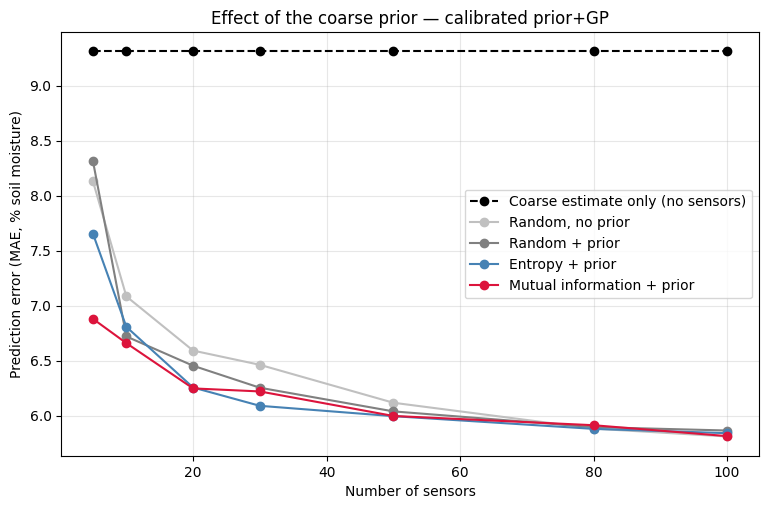

In [20]:
kern = KERNELS[BEST_MODE]
counts = [5, 10, 20, 30, 50, 80, 100]
lines = {"random, no prior": [], "random": [], "entropy": [], "mutual_info": [], "prior_only": []}

print("mode:", BEST_MODE, "\n")
for n in counts:
    errs = {}
    for k in lines:
        errs[k] = []
    wins = 0

    for run in range(50):
        rng = np.random.default_rng(run)
        order = rng.permutation(len(s12))
        test_idx = list(order[:N_TEST])
        pool = list(order[N_TEST:])

        pick = list(rng.choice(pool, n, replace=False))
        errs["random"].append(predict_mode(BEST_MODE, kern, X12, y12, p12, pick, test_idx))
        errs["random, no prior"].append(predict_mode("no_prior", KERNELS["no_prior"], X12, y12, p12, pick, test_idx))
        errs["prior_only"].append(predict_mode("prior_only", None, X12, y12, p12, pick, test_idx))

        for crit in ["entropy", "mutual_info"]:
            chosen = greedy_k(kern, X12, pool, 2, n - 2, run, crit)
            errs[crit].append(predict_mode(BEST_MODE, kern, X12, y12, p12, chosen, test_idx))

        if errs["mutual_info"][-1] < errs["random"][-1]:
            wins = wins + 1

    for k in lines:
        lines[k].append(np.mean(errs[k]))

    print(f"n={n:3d}  no-prior {np.mean(errs['random, no prior']):.2f}  |  with prior: random {np.mean(errs['random']):.2f}  "
          f"entropy {np.mean(errs['entropy']):.2f}  MI {np.mean(errs['mutual_info']):.2f}  |  MI won {wins}/50  |  "
          f"worst: random {max(errs['random']):.2f}, MI {max(errs['mutual_info']):.2f}")

styles = {"prior_only": ("black", "--", "Coarse estimate only (no sensors)"),
          "random, no prior": ("silver", "-", "Random, no prior"),
          "random": ("gray", "-", "Random + prior"),
          "entropy": ("steelblue", "-", "Entropy + prior"),
          "mutual_info": ("crimson", "-", "Mutual information + prior")}
plt.figure(figsize=(9, 5.5))
for k in styles:
    colour, ls, label = styles[k]
    plt.plot(counts, lines[k], marker="o", color=colour, linestyle=ls, label=label)
plt.xlabel("Number of sensors")
plt.ylabel("Prediction error (MAE, % soil moisture)")
plt.title(f"Effect of the coarse prior — {BEST_MODE}")
plt.legend(); plt.grid(alpha=0.3)
plt.show()

## 13. Making the result trustworthy

Four changes, all in one experiment:

1. **More months.** Same pipeline for April, June, August and October 2023, so the result can't be
   a June fluke.
2. **No leakage.** Until now the kernel was learned once from *all* stations, test ones included.
   Here it is re-learned **inside every run from the non-test stations only**. The test stations are
   never seen until they're scored.
3. **p-values.** Every "won X/50" comes with a one-sided sign-test p-value: the chance of winning
   that often if both methods were really equally good. p < 0.05 is the usual bar.
4. **Calibration-aware placement.** Section 12 showed calibration fails when the chosen stations
   all sit in similar (all-wet or all-dry) places. The new criterion adds the uncertainty of the
   calibration line itself to the GP's uncertainty (the *universal kriging* variance), so it
   deliberately picks stations that cover the range of ERA5 values as well as the map.

Also: stations with fewer than 20 days of readings in a month are dropped, so short gaps don't
dominate the average.

**Methods compared in every run (same split, same 40 test stations):**
- `random, no prior` — the original setup
- `random + prior` — random stations, calibrated prior + GP
- `MI + prior` — section 12's winner
- `calib-MI + prior` — new criterion from point 4

In [21]:
from math import comb

def sign_test_p(wins, n):
    """One-sided: chance of >= wins out of n if each run were a coin flip."""
    total = 0
    for k in range(wins, n + 1):
        total = total + comb(n, k)
    return total / (2 ** n)


def fetch_ground(begin, end, min_days=20):
    """Monthly-average SCAN moisture at 2 in, same steps as sections 2-4."""
    params = {"stationTriplets": ",".join(all_ids), "elements": ELEMENT,
              "duration": "DAILY", "beginDate": begin, "endDate": end}
    r = requests.get(DATA_URL, params=params, timeout=300)
    r.raise_for_status()
    rows = []
    for s in r.json():
        series = s.get("data", [])
        if not series:
            continue
        values = [v["value"] for v in series[0]["values"] if v.get("value") is not None]
        if len(values) < min_days:
            continue
        rows.append({"stationTriplet": s["stationTriplet"],
                     "moisture": sum(values) / len(values), "n_days": len(values)})
    df = mainland.merge(pd.DataFrame(rows), on="stationTriplet", how="inner")
    df = df[df.moisture > 0].reset_index(drop=True)
    return df


def uk_var(kernel, Xq, Xs, Fq, Fs):
    """GP variance PLUS uncertainty of the calibration line (universal kriging).
    F rows are [1, ERA5/10] - the inputs of the line station = a + b*ERA5."""
    Kss = kernel(Xs) + JITTER * np.eye(len(Xs))
    Kqs = kernel(Xq, Xs)
    A = np.linalg.solve(Kss, Kqs.T)                       # ns x nq
    gp_var = kernel.diag(Xq) - np.sum(Kqs * A.T, axis=1)
    B = np.linalg.solve(Kss, Fs)                          # ns x 2
    M = Fs.T @ B + 1e-6 * np.eye(2)                       # 2 x 2
    R = Fq - A.T @ Fs                                     # nq x 2
    trend = np.sum((R @ np.linalg.inv(M)) * R, axis=1)
    return np.maximum(gp_var + trend, 1e-12)


def greedy_calib(kernel, X_all, F_all, pool, n_start, n_add, seed):
    """Same as greedy_k with mutual_info, but the 'how unsure are we here now' part
    also counts how unsure the calibration line is."""
    rng = np.random.default_rng(seed)
    idx = np.array(pool); rng.shuffle(idx)
    known = list(idx[:n_start])
    cand = list(idx[n_start:])
    for step in range(n_add):
        if len(cand) == 0:
            break
        Xc = X_all[cand]
        var_A = uk_var(kernel, Xc, X_all[known], F_all[cand], F_all[known])
        score = var_A / var_rest_k(kernel, Xc)
        best = int(np.argmax(score))
        known.append(cand[best])
        cand.pop(best)
    return known

print("ready")

ready


In [22]:
MONTHS = [("2023-04-01", "2023-04-30", "Apr 2023"),
          ("2023-06-01", "2023-06-30", "Jun 2023"),
          ("2023-08-01", "2023-08-31", "Aug 2023"),
          ("2023-10-01", "2023-10-31", "Oct 2023")]

month_data = {}
for begin, end, label in MONTHS:
    print(f"--- {label}")
    df = fetch_ground(begin, end)
    df["era5"] = fetch_era5_month(list(df.latitude), list(df.longitude), begin=begin, end=end)
    df = df[df.era5.notna()].reset_index(drop=True)
    c = np.corrcoef(df.moisture, df.era5)[0, 1]
    print(f"{label}: {len(df)} stations, station vs ERA5 correlation {c:.2f}\n")
    month_data[label] = df

--- Apr 2023
  fetched 25/160
  fetched 50/160
  fetched 75/160
  fetched 100/160
  fetched 125/160
  fetched 150/160
  fetched 160/160
Apr 2023: 160 stations, station vs ERA5 correlation 0.54

--- Jun 2023
  fetched 25/165
  fetched 50/165
  fetched 75/165
  fetched 100/165
  fetched 125/165
  fetched 150/165
  fetched 165/165
Jun 2023: 165 stations, station vs ERA5 correlation 0.52

--- Aug 2023
  fetched 25/165
  fetched 50/165
  fetched 75/165
  fetched 100/165
  fetched 125/165
  fetched 150/165
  fetched 165/165
Aug 2023: 165 stations, station vs ERA5 correlation 0.55

--- Oct 2023
  fetched 25/164
  fetched 50/164
  fetched 75/164
  fetched 100/164
  fetched 125/164
  fetched 150/164
  fetched 164/164
Oct 2023: 164 stations, station vs ERA5 correlation 0.51



In [23]:
METHODS = ["random, no prior", "random + prior", "MI + prior", "calib-MI + prior"]
COUNTS13 = [5, 10, 20, 30]
RUNS13 = 50
setup13 = {"kernel": "matern", "coords": "deg", "elevation": False, "ard": False}


def predict_calibrated(kernel, X, y, prior, chosen, test_idx):
    a, b = linear_fit(prior[chosen], y[chosen])
    base = a + b * prior
    resid = y - base
    gp, m, s = fit_gp_k(kernel, X[chosen], resid[chosen])
    pred = base[test_idx] + gp.predict(X[test_idx]) * s + m
    return mean_absolute_error(y[test_idx], pred)


all_results = {}
for label in month_data:
    df = month_data[label]
    X = make_features(df, setup13)
    y = df["moisture"].values
    prior = df["era5"].values
    F = np.column_stack([np.ones(len(df)), prior / 10.0])

    errs = {}
    for n in COUNTS13:
        errs[n] = {}
        for m in METHODS:
            errs[n][m] = []

    for run in range(RUNS13):
        rng = np.random.default_rng(run)
        order = rng.permutation(len(df))
        test_idx = list(order[:N_TEST])
        pool = list(order[N_TEST:])

        # kernels learned from the pool only - test stations never touched
        k_plain = learn_kernel(X[pool], y[pool], setup13, restarts=1)
        a, b = linear_fit(prior[pool], y[pool])
        k_resid = learn_kernel(X[pool], (y - (a + b * prior))[pool], setup13, restarts=1)

        for n in COUNTS13:
            pick = list(rng.choice(pool, n, replace=False))
            errs[n]["random, no prior"].append(evaluate_k(k_plain, X, y, pick, test_idx))
            errs[n]["random + prior"].append(predict_calibrated(k_resid, X, y, prior, pick, test_idx))

            chosen = greedy_k(k_resid, X, pool, 2, n - 2, run, "mutual_info")
            errs[n]["MI + prior"].append(predict_calibrated(k_resid, X, y, prior, chosen, test_idx))

            chosen = greedy_calib(k_resid, X, F, pool, 2, n - 2, run)
            errs[n]["calib-MI + prior"].append(predict_calibrated(k_resid, X, y, prior, chosen, test_idx))

    all_results[label] = errs
    print(f"=== {label} ({len(df)} stations)")
    for n in COUNTS13:
        line = f"n={n:3d}  "
        for m in METHODS:
            line = line + f"{m} {np.mean(errs[n][m]):.2f}   "
        print(line)
    print()

=== Apr 2023 (160 stations)
n=  5  random, no prior 10.36   random + prior 11.37   MI + prior 9.65   calib-MI + prior 9.28   
n= 10  random, no prior 9.62   random + prior 9.07   MI + prior 8.92   calib-MI + prior 8.78   
n= 20  random, no prior 9.13   random + prior 8.54   MI + prior 8.27   calib-MI + prior 8.35   
n= 30  random, no prior 8.84   random + prior 8.27   MI + prior 8.14   calib-MI + prior 8.17   

=== Jun 2023 (165 stations)
n=  5  random, no prior 7.64   random + prior 7.71   MI + prior 6.94   calib-MI + prior 6.57   
n= 10  random, no prior 7.09   random + prior 6.69   MI + prior 6.60   calib-MI + prior 6.61   
n= 20  random, no prior 6.56   random + prior 6.40   MI + prior 6.36   calib-MI + prior 6.38   
n= 30  random, no prior 6.37   random + prior 6.20   MI + prior 6.24   calib-MI + prior 6.18   

=== Aug 2023 (165 stations)
n=  5  random, no prior 8.07   random + prior 7.90   MI + prior 7.14   calib-MI + prior 6.73   
n= 10  random, no prior 7.24   random + prior 6.

### Win counts and p-values

Each comparison is paired: same run, same test stations. "Wins" = runs where the first method had
lower error. Bold claims in the report should only use rows with p < 0.05.

In [24]:
PAIRS = [("MI + prior", "random + prior"),
         ("calib-MI + prior", "random + prior"),
         ("calib-MI + prior", "MI + prior"),
         ("calib-MI + prior", "random, no prior")]

for a_m, b_m in PAIRS:
    print(f"--- {a_m}  vs  {b_m}")
    for n in COUNTS13:
        line = f"n={n:3d}  "
        total_w = 0
        total_n = 0
        for label in all_results:
            ea = all_results[label][n][a_m]
            eb = all_results[label][n][b_m]
            w = 0
            for i in range(len(ea)):
                if ea[i] < eb[i]:
                    w = w + 1
            total_w = total_w + w
            total_n = total_n + len(ea)
            line = line + f"{label} {w}/{len(ea)} (p={sign_test_p(w, len(ea)):.3f})   "
        line = line + f"|  ALL {total_w}/{total_n} (p={sign_test_p(total_w, total_n):.4f})"
        print(line)
    print()

--- MI + prior  vs  random + prior
n=  5  Apr 2023 33/50 (p=0.016)   Jun 2023 30/50 (p=0.101)   Aug 2023 29/50 (p=0.161)   Oct 2023 28/50 (p=0.240)   |  ALL 120/200 (p=0.0028)
n= 10  Apr 2023 25/50 (p=0.556)   Jun 2023 28/50 (p=0.240)   Aug 2023 25/50 (p=0.556)   Oct 2023 29/50 (p=0.161)   |  ALL 107/200 (p=0.1790)
n= 20  Apr 2023 30/50 (p=0.101)   Jun 2023 26/50 (p=0.444)   Aug 2023 23/50 (p=0.760)   Oct 2023 33/50 (p=0.016)   |  ALL 112/200 (p=0.0518)
n= 30  Apr 2023 32/50 (p=0.032)   Jun 2023 24/50 (p=0.664)   Aug 2023 21/50 (p=0.899)   Oct 2023 24/50 (p=0.664)   |  ALL 101/200 (p=0.4718)

--- calib-MI + prior  vs  random + prior
n=  5  Apr 2023 37/50 (p=0.000)   Jun 2023 34/50 (p=0.008)   Aug 2023 36/50 (p=0.001)   Oct 2023 34/50 (p=0.008)   |  ALL 141/200 (p=0.0000)
n= 10  Apr 2023 26/50 (p=0.444)   Jun 2023 29/50 (p=0.161)   Aug 2023 34/50 (p=0.008)   Oct 2023 29/50 (p=0.161)   |  ALL 118/200 (p=0.0066)
n= 20  Apr 2023 30/50 (p=0.101)   Jun 2023 24/50 (p=0.664)   Aug 2023 20/50 (

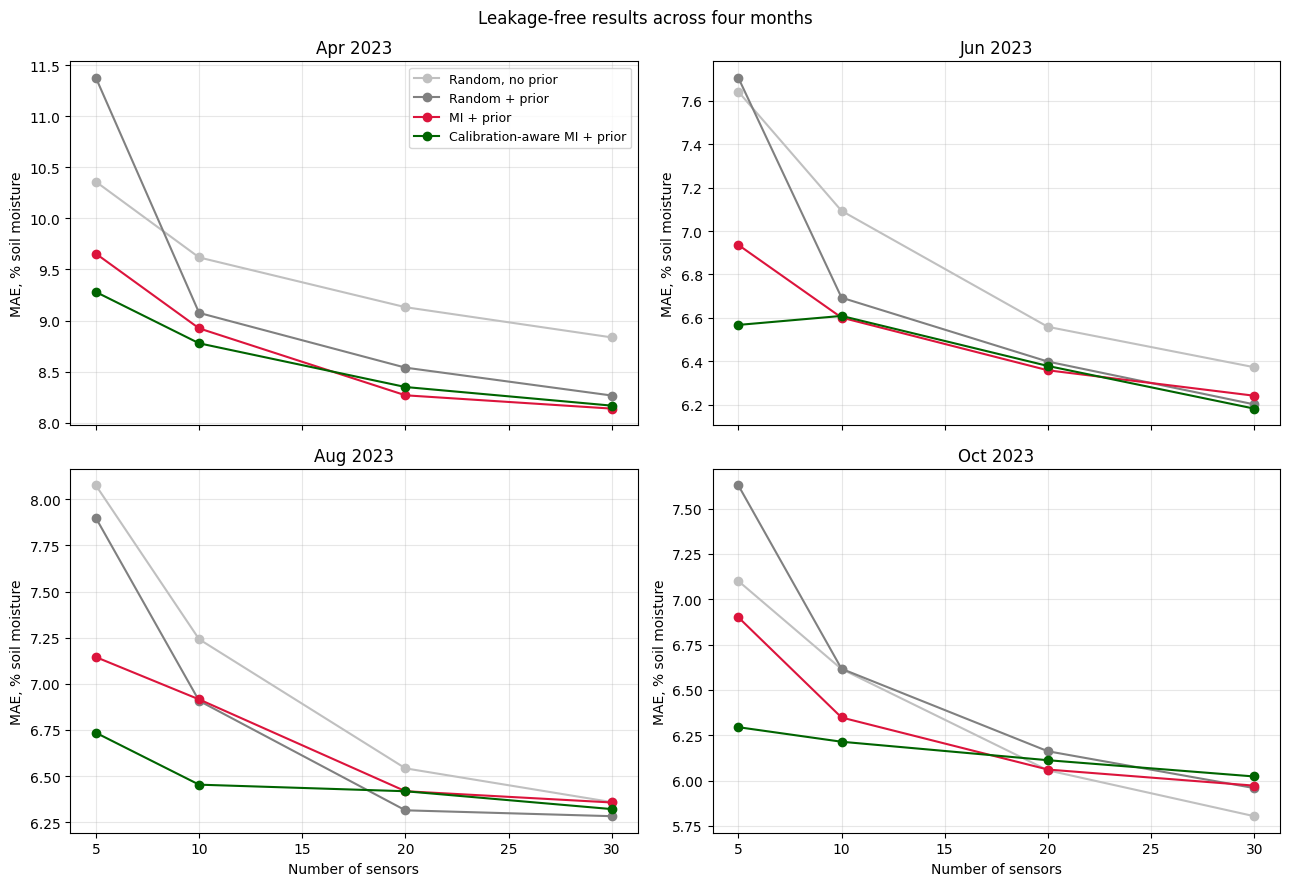

Average over the four months:
n=  5  random, no prior 8.29   random + prior 8.65   MI + prior 7.66   calib-MI + prior 7.22   
n= 10  random, no prior 7.64   random + prior 7.32   MI + prior 7.20   calib-MI + prior 7.01   
n= 20  random, no prior 7.07   random + prior 6.85   MI + prior 6.78   calib-MI + prior 6.81   
n= 30  random, no prior 6.84   random + prior 6.68   MI + prior 6.68   calib-MI + prior 6.67   


In [25]:
styles13 = {"random, no prior": ("silver", "Random, no prior"),
            "random + prior": ("gray", "Random + prior"),
            "MI + prior": ("crimson", "MI + prior"),
            "calib-MI + prior": ("darkgreen", "Calibration-aware MI + prior")}

fig, axes = plt.subplots(2, 2, figsize=(13, 9), sharex=True)
labels = list(all_results)
for i in range(len(labels)):
    ax = axes[i // 2][i % 2]
    errs = all_results[labels[i]]
    for m in METHODS:
        colour, name = styles13[m]
        mu = [np.mean(errs[n][m]) for n in COUNTS13]
        ax.plot(COUNTS13, mu, marker="o", color=colour, label=name)
    ax.set_title(labels[i]); ax.grid(alpha=0.3)
    ax.set_ylabel("MAE, % soil moisture")
axes[1][0].set_xlabel("Number of sensors"); axes[1][1].set_xlabel("Number of sensors")
axes[0][0].legend(fontsize=9)
plt.suptitle("Leakage-free results across four months")
plt.tight_layout(); plt.show()

print("Average over the four months:")
for n in COUNTS13:
    line = f"n={n:3d}  "
    for m in METHODS:
        avg = 0.0
        for label in labels:
            avg = avg + np.mean(all_results[label][n][m])
        line = line + f"{m} {avg / len(labels):.2f}   "
    print(line)

## 14. Real satellite data: NASA SMAP

Everything so far used ERA5-Land, which is a *reanalysis* (a land-surface model fed with weather
observations), not a satellite. Here we add the real thing: **NASA SMAP** (Soil Moisture Active
Passive), product **SPL3SMP** — daily soil moisture from the SMAP L-band radiometer on a 36 km grid.

Then we run the section 13 experiment again, on the **same stations and the same random splits**,
once with ERA5 as the prior and once with SMAP, so the two are directly comparable.

**Before running:** make a free NASA Earthdata account at https://urs.earthdata.nasa.gov (takes a
minute). The next cell will ask for the username and password.

Notes for the report:
- SMAP gives up to two readings per day (6 am and 6 pm passes). We average every valid reading in
  the month for each grid cell.
- 36 km cells are much coarser than ERA5-Land's ~9 km — this is the "wide but inaccurate" source
  from the proposal in its purest form.
- Values outside 0.02–0.60 m³/m³ are treated as invalid (frozen ground, open water, failed retrievals).

In [26]:
!pip -q install earthaccess
import earthaccess, h5py, os, glob, getpass

os.environ["EARTHDATA_USERNAME"] = input("Earthdata username: ")
os.environ["EARTHDATA_PASSWORD"] = getpass.getpass("Earthdata password: ")
auth = earthaccess.login(strategy="environment")
print("logged in:", auth.authenticated)

Earthdata username: (hidden)
Earthdata password: ··········
logged in: True


In [27]:
SMAP_DIR = "/content/smap"


def _pick(group, names):
    """Return the first dataset in this HDF5 group whose name is in 'names' (names differ by version)."""
    for nm in names:
        if nm in group:
            return group[nm][()]
    return None


def smap_month_grid(begin, end):
    """Monthly-mean SMAP soil moisture (%) on the 36 km grid, plus the latitude of each row
    and longitude of each column. Downloads the daily files, averages, then deletes them."""
    results = earthaccess.search_data(short_name="SPL3SMP", version="009", temporal=(begin, end))
    if len(results) == 0:
        results = earthaccess.search_data(short_name="SPL3SMP", temporal=(begin, end))
    print(f"  {len(results)} daily SMAP files for {begin} to {end}")
    os.makedirs(SMAP_DIR, exist_ok=True)
    files = earthaccess.download(results, local_path=SMAP_DIR)

    total = None
    count = None
    row_lat = None
    col_lon = None
    for f in files:
        with h5py.File(f, "r") as h:
            for grp_name, sfx in [("Soil_Moisture_Retrieval_Data_AM", ""), ("Soil_Moisture_Retrieval_Data_PM", "_pm")]:
                if grp_name not in h:
                    continue
                g = h[grp_name]
                sm = _pick(g, ["soil_moisture" + sfx, "soil_moisture", "soil_moisture_dca" + sfx, "soil_moisture_dca"])
                lat = _pick(g, ["latitude" + sfx, "latitude"])
                lon = _pick(g, ["longitude" + sfx, "longitude"])
                if sm is None or lat is None or lon is None:
                    continue
                if total is None:
                    total = np.zeros(sm.shape)
                    count = np.zeros(sm.shape)
                    row_lat = np.full(sm.shape[0], np.nan)
                    col_lon = np.full(sm.shape[1], np.nan)
                valid = (sm >= 0.02) & (sm <= 0.60)
                total[valid] = total[valid] + sm[valid]
                count[valid] = count[valid] + 1

                # every cell in a row has the same latitude, every cell in a column the same longitude
                lat_ok = np.where(lat > -999, lat, np.nan)
                lon_ok = np.where(lon > -999, lon, np.nan)
                with np.errstate(all="ignore"):
                    rl = np.nanmax(lat_ok, axis=1)
                    cl = np.nanmax(lon_ok, axis=0)
                row_lat = np.where(np.isnan(row_lat), rl, row_lat)
                col_lon = np.where(np.isnan(col_lon), cl, col_lon)
        os.remove(f)                                    # save disk space

    mean = np.full(total.shape, np.nan)
    has = count > 0
    mean[has] = 100.0 * total[has] / count[has]         # m3/m3 -> %
    return mean, row_lat, col_lon


def smap_at(mean, row_lat, col_lon, lats, lons):
    """Value of the nearest SMAP cell for each point (NaN if that cell had no valid reading)."""
    out = np.full(len(lats), np.nan)
    for i in range(len(lats)):
        r = int(np.nanargmin(np.abs(row_lat - lats[i])))
        c = int(np.nanargmin(np.abs(col_lon - lons[i])))
        out[i] = mean[r, c]
    return out


month_data14 = {}
smap_grids = {}
for begin, end, label in MONTHS:
    print(f"--- {label}")
    mean, row_lat, col_lon = smap_month_grid(begin, end)
    smap_grids[label] = (mean, row_lat, col_lon)
    df = month_data[label].copy()
    df["smap"] = smap_at(mean, row_lat, col_lon, list(df.latitude), list(df.longitude))
    df = df[df.smap.notna() & df.era5.notna()].reset_index(drop=True)   # same stations for both priors
    month_data14[label] = df
    cE = np.corrcoef(df.moisture, df.era5)[0, 1]
    cS = np.corrcoef(df.moisture, df.smap)[0, 1]
    print(f"{label}: {len(df)} stations with both | correlation with stations: ERA5 {cE:.2f}, SMAP {cS:.2f}\n")

# keep June SMAP in the saved CSV too (for the app)
jm, jr, jc = smap_grids["Jun 2023"]
sensors["smap"] = smap_at(jm, jr, jc, list(sensors.latitude), list(sensors.longitude))

--- Apr 2023
  30 daily SMAP files for 2023-04-01 to 2023-04-30


QUEUEING TASKS | :   0%|          | 0/30 [00:00<?, ?it/s]

PROCESSING TASKS | :   0%|          | 0/30 [00:00<?, ?it/s]

COLLECTING RESULTS | :   0%|          | 0/30 [00:00<?, ?it/s]

Apr 2023: 155 stations with both | correlation with stations: ERA5 0.55, SMAP 0.59

--- Jun 2023
  30 daily SMAP files for 2023-06-01 to 2023-06-30


...

Aug 2023: 165 stations with both | correlation with stations: ERA5 0.55, SMAP 0.48

--- Oct 2023
  31 daily SMAP files for 2023-10-01 to 2023-10-31


QUEUEING TASKS | :   0%|          | 0/31 [00:00<?, ?it/s]

PROCESSING TASKS | :   0%|          | 0/31 [00:00<?, ?it/s]

COLLECTING RESULTS | :   0%|          | 0/31 [00:00<?, ?it/s]

Oct 2023: 164 stations with both | correlation with stations: ERA5 0.51, SMAP 0.52



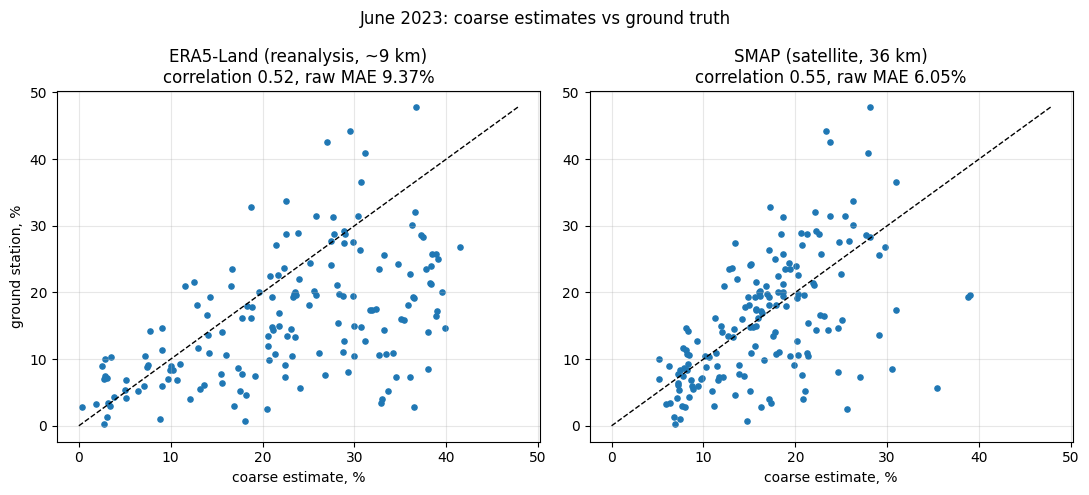

In [28]:
fig, axes = plt.subplots(1, 2, figsize=(11, 5))
dfj = month_data14["Jun 2023"]
for ax, col, name in [(axes[0], "era5", "ERA5-Land (reanalysis, ~9 km)"), (axes[1], "smap", "SMAP (satellite, 36 km)")]:
    ax.scatter(dfj[col], dfj.moisture, s=14)
    lim = max(dfj[col].max(), dfj.moisture.max())
    ax.plot([0, lim], [0, lim], "k--", lw=1)
    c = np.corrcoef(dfj.moisture, dfj[col])[0, 1]
    mae = np.mean(np.abs(dfj.moisture - dfj[col]))
    ax.set_title(f"{name}\ncorrelation {c:.2f}, raw MAE {mae:.2f}%")
    ax.set_xlabel("coarse estimate, %"); ax.grid(alpha=0.3)
axes[0].set_ylabel("ground station, %")
plt.suptitle("June 2023: coarse estimates vs ground truth"); plt.tight_layout(); plt.show()

### Same experiment, two priors

For every run: same 40 test stations, same random picks. Each prior gets its own calibration line and
kernel, learned from the pool only (no leakage). Methods:
- `random, no prior` — shared baseline
- `random + ERA5`, `calib-MI + ERA5`
- `random + SMAP`, `calib-MI + SMAP`

In [29]:
METHODS14 = ["random, no prior", "random + ERA5", "calib-MI + ERA5", "random + SMAP", "calib-MI + SMAP"]
PRIORS = [("ERA5", "era5"), ("SMAP", "smap")]
results14 = {}

for label in month_data14:
    df = month_data14[label]
    X = make_features(df, setup13)
    y = df["moisture"].values

    errs = {}
    for n in COUNTS13:
        errs[n] = {}
        for m in METHODS14:
            errs[n][m] = []

    for run in range(RUNS13):
        rng = np.random.default_rng(run)
        order = rng.permutation(len(df))
        test_idx = list(order[:N_TEST])
        pool = list(order[N_TEST:])

        k_plain = learn_kernel(X[pool], y[pool], setup13, restarts=1)
        k_prior = {}
        for pname, col in PRIORS:
            p = df[col].values
            a, b = linear_fit(p[pool], y[pool])
            k_prior[pname] = learn_kernel(X[pool], (y - (a + b * p))[pool], setup13, restarts=1)

        for n in COUNTS13:
            pick = list(rng.choice(pool, n, replace=False))
            errs[n]["random, no prior"].append(evaluate_k(k_plain, X, y, pick, test_idx))
            for pname, col in PRIORS:
                p = df[col].values
                F = np.column_stack([np.ones(len(df)), p / 10.0])
                kk = k_prior[pname]
                errs[n]["random + " + pname].append(predict_calibrated(kk, X, y, p, pick, test_idx))
                chosen = greedy_calib(kk, X, F, pool, 2, n - 2, run)
                errs[n]["calib-MI + " + pname].append(predict_calibrated(kk, X, y, p, chosen, test_idx))

    results14[label] = errs
    print(f"=== {label} ({len(df)} stations)")
    for n in COUNTS13:
        line = f"n={n:3d}  "
        for m in METHODS14:
            line = line + f"{m} {np.mean(errs[n][m]):.2f}   "
        print(line)
    print()

=== Apr 2023 (155 stations)
n=  5  random, no prior 10.55   random + ERA5 11.66   calib-MI + ERA5 9.03   random + SMAP 10.57   calib-MI + SMAP 9.38   
n= 10  random, no prior 9.69   random + ERA5 9.32   calib-MI + ERA5 8.66   random + SMAP 8.63   calib-MI + SMAP 8.56   
n= 20  random, no prior 9.11   random + ERA5 8.36   calib-MI + ERA5 8.21   random + SMAP 8.34   calib-MI + SMAP 8.16   
n= 30  random, no prior 8.80   random + ERA5 8.20   calib-MI + ERA5 8.04   random + SMAP 8.07   calib-MI + SMAP 7.99   

=== Jun 2023 (165 stations)
n=  5  random, no prior 7.64   random + ERA5 7.71   calib-MI + ERA5 6.57   random + SMAP 7.54   calib-MI + SMAP 7.24   
n= 10  random, no prior 7.09   random + ERA5 6.69   calib-MI + ERA5 6.61   random + SMAP 6.69   calib-MI + SMAP 6.76   
n= 20  random, no prior 6.56   random + ERA5 6.40   calib-MI + ERA5 6.38   random + SMAP 6.31   calib-MI + SMAP 6.40   
n= 30  random, no prior 6.37   random + ERA5 6.20   calib-MI + ERA5 6.18   random + SMAP 6.08   cali

--- calib-MI + SMAP  vs  random, no prior
n=  5  Apr 2023 39/50 (p=0.000)   Jun 2023 30/50 (p=0.101)   Aug 2023 33/50 (p=0.016)   Oct 2023 38/50 (p=0.000)   |  ALL 140/200 (p=0.0000)
n= 10  Apr 2023 42/50 (p=0.000)   Jun 2023 31/50 (p=0.059)   Aug 2023 24/50 (p=0.664)   Oct 2023 29/50 (p=0.161)   |  ALL 126/200 (p=0.0001)
n= 20  Apr 2023 43/50 (p=0.000)   Jun 2023 28/50 (p=0.240)   Aug 2023 16/50 (p=0.997)   Oct 2023 29/50 (p=0.161)   |  ALL 116/200 (p=0.0141)
n= 30  Apr 2023 45/50 (p=0.000)   Jun 2023 27/50 (p=0.336)   Aug 2023 15/50 (p=0.999)   Oct 2023 25/50 (p=0.556)   |  ALL 112/200 (p=0.0518)

--- calib-MI + SMAP  vs  random + SMAP
n=  5  Apr 2023 32/50 (p=0.032)   Jun 2023 23/50 (p=0.760)   Aug 2023 33/50 (p=0.016)   Oct 2023 38/50 (p=0.000)   |  ALL 126/200 (p=0.0001)
n= 10  Apr 2023 24/50 (p=0.664)   Jun 2023 24/50 (p=0.664)   Aug 2023 30/50 (p=0.101)   Oct 2023 26/50 (p=0.444)   |  ALL 104/200 (p=0.3104)
n= 20  Apr 2023 34/50 (p=0.008)   Jun 2023 22/50 (p=0.839)   Aug 2023 23

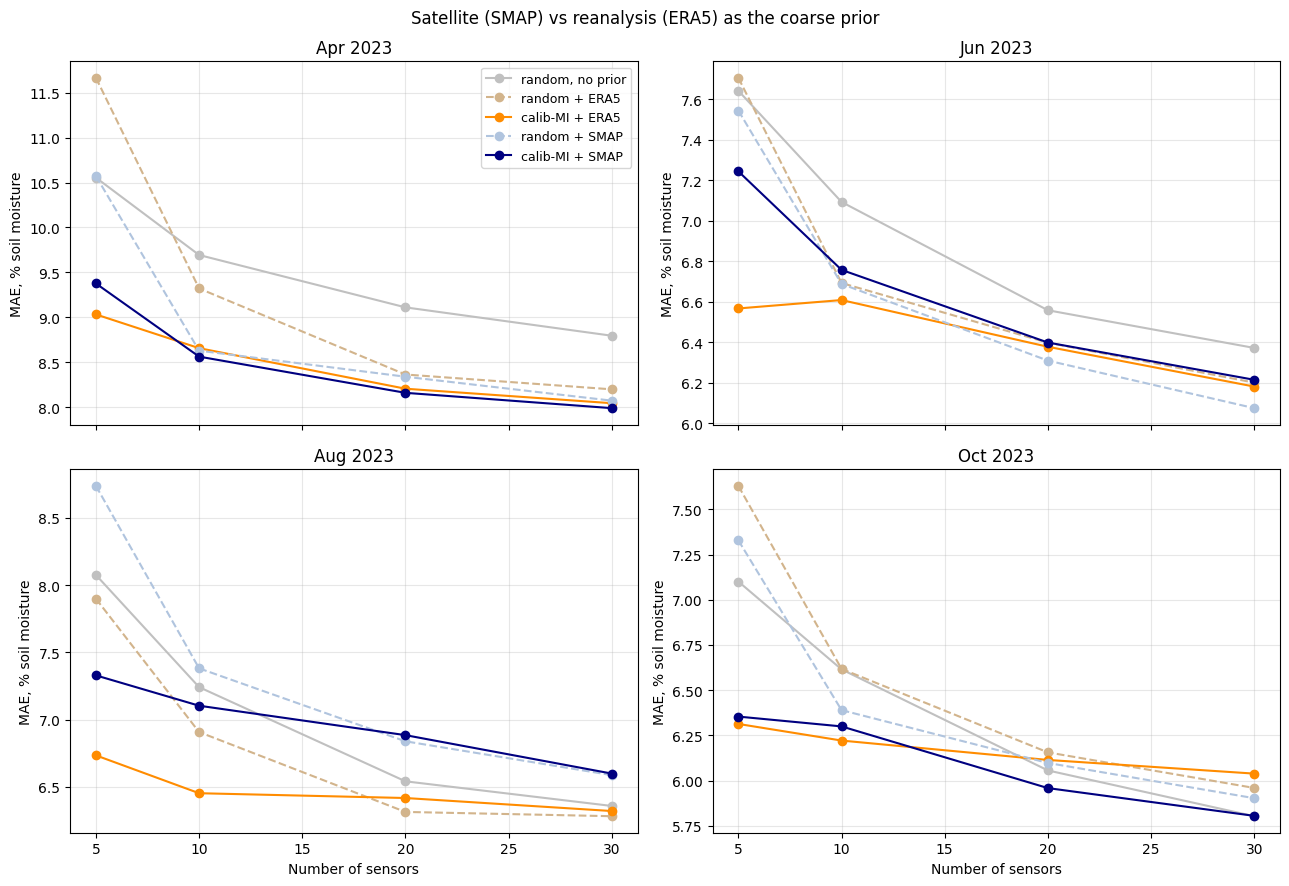

In [30]:
PAIRS14 = [("calib-MI + SMAP", "random, no prior"),
           ("calib-MI + SMAP", "random + SMAP"),
           ("calib-MI + SMAP", "calib-MI + ERA5")]

for a_m, b_m in PAIRS14:
    print(f"--- {a_m}  vs  {b_m}")
    for n in COUNTS13:
        line = f"n={n:3d}  "
        total_w = 0
        total_n = 0
        for label in results14:
            ea = results14[label][n][a_m]
            eb = results14[label][n][b_m]
            w = 0
            for i in range(len(ea)):
                if ea[i] < eb[i]:
                    w = w + 1
            total_w = total_w + w
            total_n = total_n + len(ea)
            line = line + f"{label} {w}/{len(ea)} (p={sign_test_p(w, len(ea)):.3f})   "
        line = line + f"|  ALL {total_w}/{total_n} (p={sign_test_p(total_w, total_n):.4f})"
        print(line)
    print()

print("Average over the four months:")
for n in COUNTS13:
    line = f"n={n:3d}  "
    for m in METHODS14:
        avg = 0.0
        for label in results14:
            avg = avg + np.mean(results14[label][n][m])
        line = line + f"{m} {avg / len(results14):.2f}   "
    print(line)

styles14 = {"random, no prior": ("silver", "-"), "random + ERA5": ("tan", "--"), "calib-MI + ERA5": ("darkorange", "-"),
            "random + SMAP": ("lightsteelblue", "--"), "calib-MI + SMAP": ("navy", "-")}
fig, axes = plt.subplots(2, 2, figsize=(13, 9), sharex=True)
labels14 = list(results14)
for i in range(len(labels14)):
    ax = axes[i // 2][i % 2]
    for m in METHODS14:
        colour, ls = styles14[m]
        ax.plot(COUNTS13, [np.mean(results14[labels14[i]][n][m]) for n in COUNTS13],
                marker="o", color=colour, linestyle=ls, label=m)
    ax.set_title(labels14[i]); ax.grid(alpha=0.3); ax.set_ylabel("MAE, % soil moisture")
axes[1][0].set_xlabel("Number of sensors"); axes[1][1].set_xlabel("Number of sensors")
axes[0][0].legend(fontsize=9)
plt.suptitle("Satellite (SMAP) vs reanalysis (ERA5) as the coarse prior"); plt.tight_layout(); plt.show()

## 15. "Spread them out evenly" baselines (k-means)

The obvious question a reviewer will ask: *do you need a Gaussian Process to place sensors, or would
simply spreading them out evenly do just as well?* Two simple, strong baselines answer that:

- **k-means (space):** split the candidate stations into N geographic clusters and put one sensor at
  the station nearest each cluster centre. This spreads sensors evenly over the map.
- **k-means (space + wetness):** same, but clusters on longitude, latitude **and** the ERA5 value
  (all standardised). This spreads sensors over the map *and* over wet and dry areas — a simple
  heuristic version of what calibration-aware MI does.

Every method uses the **same prediction model** (calibrated ERA5 prior + GP), the same splits, the same
40 test stations and kernels learned from the pool only — so the only thing that differs is *where the
sensors go*.

In [31]:
from sklearn.cluster import KMeans


def kmeans_pick(feats, pool, n, seed):
    """Cluster the pool into n groups; return the pool station nearest each cluster centre."""
    F = feats[pool]
    km = KMeans(n_clusters=n, n_init=10, random_state=seed).fit(F)
    chosen = []
    for c in range(n):
        centre = km.cluster_centers_[c]
        best = None
        best_d = 1e18
        for j in range(len(pool)):
            if pool[j] in chosen:
                continue
            d = np.sum((F[j] - centre) ** 2)
            if d < best_d:
                best_d = d
                best = pool[j]
        chosen.append(best)
    return chosen


METHODS15 = ["random + prior", "k-means (space) + prior", "k-means (space+wetness) + prior", "calib-MI + prior"]
results15 = {}

for label in month_data:
    df = month_data[label]
    X = make_features(df, setup13)
    y = df["moisture"].values
    prior = df["era5"].values
    F = np.column_stack([np.ones(len(df)), prior / 10.0])

    errs = {}
    for n in COUNTS13:
        errs[n] = {}
        for m in METHODS15:
            errs[n][m] = []

    for run in range(RUNS13):
        rng = np.random.default_rng(run)
        order = rng.permutation(len(df))
        test_idx = list(order[:N_TEST])
        pool = list(order[N_TEST:])

        a, b = linear_fit(prior[pool], y[pool])
        k_resid = learn_kernel(X[pool], (y - (a + b * prior))[pool], setup13, restarts=1)

        # features for k-means, standardised with pool statistics only
        geo = np.column_stack([df.longitude.values, df.latitude.values])
        geo_wet = np.column_stack([df.longitude.values, df.latitude.values, prior])
        mu = geo_wet[pool].mean(axis=0)
        sd = geo_wet[pool].std(axis=0)
        geo_wet = (geo_wet - mu) / sd

        for n in COUNTS13:
            pick = list(rng.choice(pool, n, replace=False))
            errs[n]["random + prior"].append(predict_calibrated(k_resid, X, y, prior, pick, test_idx))

            km1 = kmeans_pick(geo, pool, n, run)
            errs[n]["k-means (space) + prior"].append(predict_calibrated(k_resid, X, y, prior, km1, test_idx))

            km2 = kmeans_pick(geo_wet, pool, n, run)
            errs[n]["k-means (space+wetness) + prior"].append(predict_calibrated(k_resid, X, y, prior, km2, test_idx))

            chosen = greedy_calib(k_resid, X, F, pool, 2, n - 2, run)
            errs[n]["calib-MI + prior"].append(predict_calibrated(k_resid, X, y, prior, chosen, test_idx))

    results15[label] = errs
    print(f"=== {label} ({len(df)} stations)")
    for n in COUNTS13:
        line = f"n={n:3d}  "
        for m in METHODS15:
            line = line + f"{m} {np.mean(errs[n][m]):.2f}   "
        print(line)
    print()

=== Apr 2023 (160 stations)
n=  5  random + prior 11.37   k-means (space) + prior 10.33   k-means (space+wetness) + prior 9.38   calib-MI + prior 9.26   
n= 10  random + prior 9.08   k-means (space) + prior 8.42   k-means (space+wetness) + prior 8.70   calib-MI + prior 8.74   
n= 20  random + prior 8.54   k-means (space) + prior 8.41   k-means (space+wetness) + prior 8.38   calib-MI + prior 8.35   
n= 30  random + prior 8.27   k-means (space) + prior 8.41   k-means (space+wetness) + prior 8.28   calib-MI + prior 8.16   

=== Jun 2023 (165 stations)
n=  5  random + prior 7.71   k-means (space) + prior 7.10   k-means (space+wetness) + prior 6.77   calib-MI + prior 6.57   
n= 10  random + prior 6.69   k-means (space) + prior 6.85   k-means (space+wetness) + prior 7.00   calib-MI + prior 6.61   
n= 20  random + prior 6.40   k-means (space) + prior 6.47   k-means (space+wetness) + prior 6.53   calib-MI + prior 6.38   
n= 30  random + prior 6.20   k-means (space) + prior 6.32   k-means (spac

--- calib-MI + prior  vs  k-means (space) + prior
n=  5  Apr 2023 31/50 (p=0.059)   Jun 2023 29/50 (p=0.161)   Aug 2023 34/50 (p=0.008)   Oct 2023 35/50 (p=0.003)   |  ALL 129/200 (p=0.0000)
n= 10  Apr 2023 17/50 (p=0.992)   Jun 2023 28/50 (p=0.240)   Aug 2023 29/50 (p=0.161)   Oct 2023 30/50 (p=0.101)   |  ALL 104/200 (p=0.3104)
n= 20  Apr 2023 28/50 (p=0.240)   Jun 2023 30/50 (p=0.101)   Aug 2023 24/50 (p=0.664)   Oct 2023 28/50 (p=0.240)   |  ALL 110/200 (p=0.0895)
n= 30  Apr 2023 31/50 (p=0.059)   Jun 2023 29/50 (p=0.161)   Aug 2023 25/50 (p=0.556)   Oct 2023 28/50 (p=0.240)   |  ALL 113/200 (p=0.0384)

--- calib-MI + prior  vs  k-means (space+wetness) + prior
n=  5  Apr 2023 24/50 (p=0.664)   Jun 2023 28/50 (p=0.240)   Aug 2023 46/50 (p=0.000)   Oct 2023 34/50 (p=0.008)   |  ALL 132/200 (p=0.0000)
n= 10  Apr 2023 24/50 (p=0.664)   Jun 2023 33/50 (p=0.016)   Aug 2023 33/50 (p=0.016)   Oct 2023 39/50 (p=0.000)   |  ALL 129/200 (p=0.0000)
n= 20  Apr 2023 27/50 (p=0.336)   Jun 2023 32

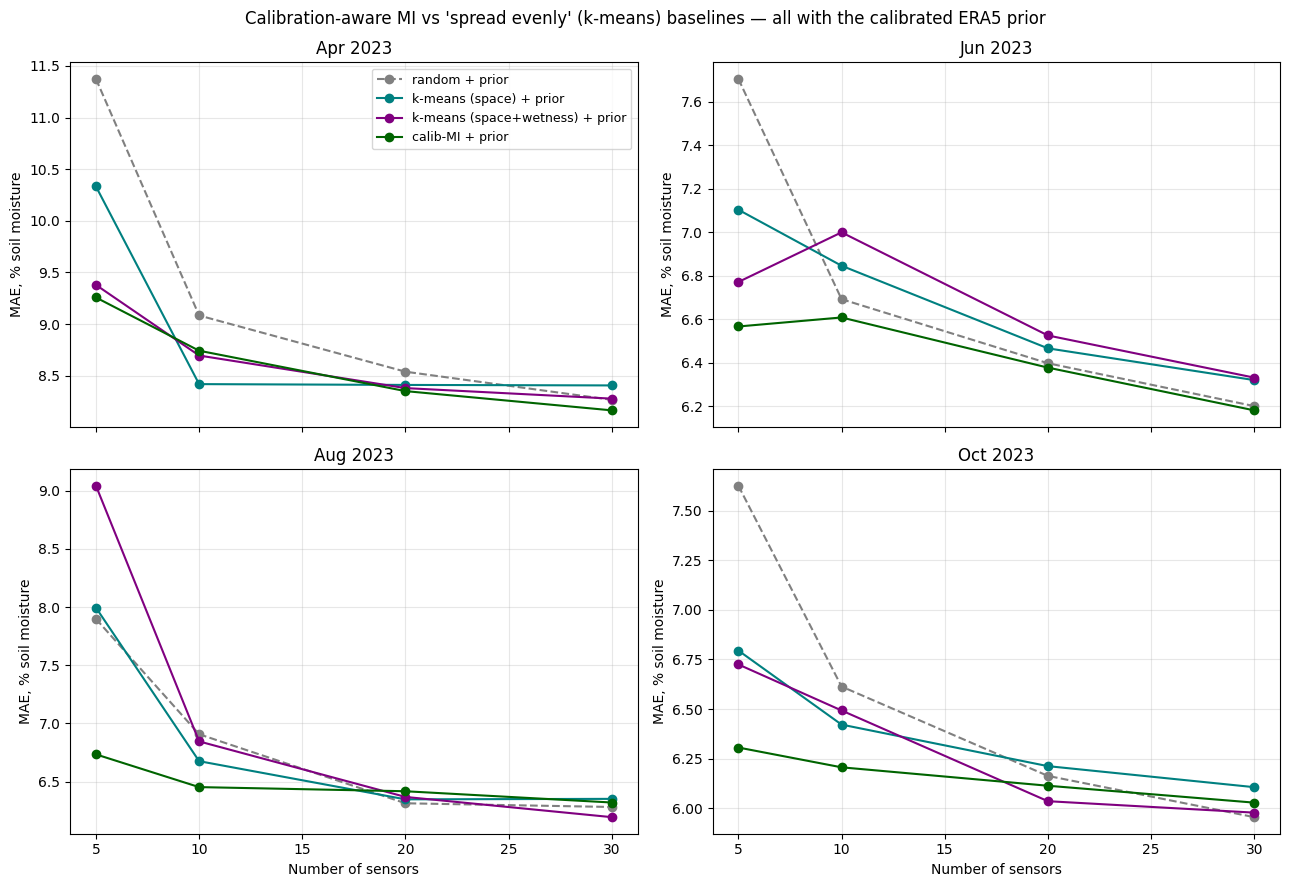

In [32]:
PAIRS15 = [("calib-MI + prior", "k-means (space) + prior"),
           ("calib-MI + prior", "k-means (space+wetness) + prior"),
           ("k-means (space) + prior", "random + prior"),
           ("k-means (space+wetness) + prior", "random + prior")]

for a_m, b_m in PAIRS15:
    print(f"--- {a_m}  vs  {b_m}")
    for n in COUNTS13:
        line = f"n={n:3d}  "
        total_w = 0
        total_n = 0
        for label in results15:
            ea = results15[label][n][a_m]
            eb = results15[label][n][b_m]
            w = 0
            for i in range(len(ea)):
                if ea[i] < eb[i]:
                    w = w + 1
            total_w = total_w + w
            total_n = total_n + len(ea)
            line = line + f"{label} {w}/{len(ea)} (p={sign_test_p(w, len(ea)):.3f})   "
        line = line + f"|  ALL {total_w}/{total_n} (p={sign_test_p(total_w, total_n):.4f})"
        print(line)
    print()

print("Average over the four months:")
for n in COUNTS13:
    line = f"n={n:3d}  "
    for m in METHODS15:
        avg = 0.0
        for label in results15:
            avg = avg + np.mean(results15[label][n][m])
        line = line + f"{m} {avg / len(results15):.2f}   "
    print(line)

styles15 = {"random + prior": ("gray", "--"), "k-means (space) + prior": ("teal", "-"),
            "k-means (space+wetness) + prior": ("purple", "-"), "calib-MI + prior": ("darkgreen", "-")}
fig, axes = plt.subplots(2, 2, figsize=(13, 9), sharex=True)
labels15 = list(results15)
for i in range(len(labels15)):
    ax = axes[i // 2][i % 2]
    for m in METHODS15:
        colour, ls = styles15[m]
        ax.plot(COUNTS13, [np.mean(results15[labels15[i]][n][m]) for n in COUNTS13],
                marker="o", color=colour, linestyle=ls, label=m)
    ax.set_title(labels15[i]); ax.grid(alpha=0.3); ax.set_ylabel("MAE, % soil moisture")
axes[1][0].set_xlabel("Number of sensors"); axes[1][1].set_xlabel("Number of sensors")
axes[0][0].legend(fontsize=9)
plt.suptitle("Calibration-aware MI vs 'spread evenly' (k-means) baselines — all with the calibrated ERA5 prior")
plt.tight_layout(); plt.show()

## 16. Strict evaluation: kernel learned from the PREVIOUS YEAR

In sections 13–15 the kernel is re-learned in every run from the non-test stations only, so the 40 test
stations are never seen. A stricter reviewer can still say: *"the kernel used the readings of ~120
pool stations, but a genuinely sparse network would only have the handful of sensors you placed."*

This section removes that completely:
- The GP kernel (length-scale, signal and noise levels) is learned **once per month from 2022 data**
  — the same month, one year earlier. This is *historical* data a real planner would already have.
- In the 2023 experiment, the **only** 2023 readings any method sees are those of the sensors it
  chose. The calibration line `station ≈ a + b·ERA5` is fitted on the chosen sensors only.
- k-means only uses station locations and ERA5 values (which are public), never station readings.

So nothing from a 2023 non-chosen station — test or pool — influences any prediction.

In [33]:
MONTHS_HIST = [("2022-04-01", "2022-04-30", "Apr 2023"),
               ("2022-06-01", "2022-06-30", "Jun 2023"),
               ("2022-08-01", "2022-08-31", "Aug 2023"),
               ("2022-10-01", "2022-10-31", "Oct 2023")]   # label = the 2023 month it is used for

hist_kernels = {}
for begin, end, label in MONTHS_HIST:
    print(f"--- {begin[:7]} (historical data for {label})")
    h = fetch_ground(begin, end)
    h["era5"] = fetch_era5_month(list(h.latitude), list(h.longitude), begin=begin, end=end)
    h = h[h.era5.notna()].reset_index(drop=True)
    Xh = make_features(h, setup13)
    yh = h["moisture"].values
    ph = h["era5"].values
    a_h, b_h = linear_fit(ph, yh)
    resid_h = yh - (a_h + b_h * ph)
    hist_kernels[label] = {
        "plain": learn_kernel(Xh, yh, setup13, restarts=3),
        "resid": learn_kernel(Xh, resid_h, setup13, restarts=3),
        "resid_std": float(resid_h.std()),
        "n": len(h),
    }
    print(f"   {len(h)} stations | residual kernel: {hist_kernels[label]['resid']}\n")

--- 2022-04 (historical data for Apr 2023)
  fetched 25/166
  fetched 50/166
  fetched 75/166
  fetched 100/166
  fetched 125/166
  fetched 150/166
  fetched 166/166
   166 stations | residual kernel: 0.592**2 * Matern(length_scale=1.05, nu=1.5) + WhiteKernel(noise_level=0.593)

--- 2022-06 (historical data for Jun 2023)
  fetched 25/160
  fetched 50/160
  fetched 75/160
  fetched 100/160
  fetched 125/160
  fetched 150/160
  fetched 160/160
   160 stations | residual kernel: 0.597**2 * Matern(length_scale=1.59, nu=1.5) + WhiteKernel(noise_level=0.564)

--- 2022-08 (historical data for Aug 2023)
  fetched 25/155
  fetched 50/155
  fetched 75/155
  fetched 100/155
  fetched 125/155
  fetched 150/155
  fetched 155/155
   155 stations | residual kernel: 0.463**2 * Matern(length_scale=1.24, nu=1.5) + WhiteKernel(noise_level=0.774)

--- 2022-10 (historical data for Oct 2023)
  fetched 25/160
  fetched 50/160
  fetched 75/160
  fetched 100/160
  fetched 125/160
  fetched 150/160
  fetched 16

In [34]:
METHODS16 = ["random, no prior", "random + prior", "k-means (space) + prior",
             "k-means (space+wetness) + prior", "MI + prior", "calib-MI + prior"]
results16 = {}

for label in month_data:
    df = month_data[label]
    X = make_features(df, setup13)
    y = df["moisture"].values
    prior = df["era5"].values
    F = np.column_stack([np.ones(len(df)), prior / 10.0])
    k_plain = hist_kernels[label]["plain"]
    k_resid = hist_kernels[label]["resid"]

    errs = {}
    for n in COUNTS13:
        errs[n] = {}
        for m in METHODS16:
            errs[n][m] = []

    for run in range(RUNS13):
        rng = np.random.default_rng(run)
        order = rng.permutation(len(df))
        test_idx = list(order[:N_TEST])
        pool = list(order[N_TEST:])

        geo = np.column_stack([df.longitude.values, df.latitude.values])
        geo_wet = np.column_stack([df.longitude.values, df.latitude.values, prior])
        mu = geo_wet[pool].mean(axis=0)
        sd = geo_wet[pool].std(axis=0)
        geo_wet = (geo_wet - mu) / sd

        for n in COUNTS13:
            pick = list(rng.choice(pool, n, replace=False))
            errs[n]["random, no prior"].append(evaluate_k(k_plain, X, y, pick, test_idx))
            errs[n]["random + prior"].append(predict_calibrated(k_resid, X, y, prior, pick, test_idx))

            km1 = kmeans_pick(geo, pool, n, run)
            errs[n]["k-means (space) + prior"].append(predict_calibrated(k_resid, X, y, prior, km1, test_idx))
            km2 = kmeans_pick(geo_wet, pool, n, run)
            errs[n]["k-means (space+wetness) + prior"].append(predict_calibrated(k_resid, X, y, prior, km2, test_idx))

            mi = greedy_k(k_resid, X, pool, 2, n - 2, run, "mutual_info")
            errs[n]["MI + prior"].append(predict_calibrated(k_resid, X, y, prior, mi, test_idx))
            cm = greedy_calib(k_resid, X, F, pool, 2, n - 2, run)
            errs[n]["calib-MI + prior"].append(predict_calibrated(k_resid, X, y, prior, cm, test_idx))

    results16[label] = errs
    print(f"=== {label} ({len(df)} stations, kernel from {label[:3]} 2022)")
    for n in COUNTS13:
        line = f"n={n:3d}  "
        for m in METHODS16:
            line = line + f"{m} {np.mean(errs[n][m]):.2f}   "
        print(line)
    print()

=== Apr 2023 (160 stations, kernel from Apr 2022)
n=  5  random, no prior 10.26   random + prior 11.37   k-means (space) + prior 10.32   k-means (space+wetness) + prior 9.36   MI + prior 9.45   calib-MI + prior 9.38   
n= 10  random, no prior 9.39   random + prior 9.04   k-means (space) + prior 8.37   k-means (space+wetness) + prior 8.65   MI + prior 8.91   calib-MI + prior 8.75   
n= 20  random, no prior 9.00   random + prior 8.47   k-means (space) + prior 8.36   k-means (space+wetness) + prior 8.30   MI + prior 8.14   calib-MI + prior 8.29   
n= 30  random, no prior 8.68   random + prior 8.17   k-means (space) + prior 8.34   k-means (space+wetness) + prior 8.19   MI + prior 8.02   calib-MI + prior 8.02   

=== Jun 2023 (165 stations, kernel from Jun 2022)
n=  5  random, no prior 7.63   random + prior 7.70   k-means (space) + prior 7.09   k-means (space+wetness) + prior 6.78   MI + prior 6.99   calib-MI + prior 6.79   
n= 10  random, no prior 7.06   random + prior 6.69   k-means (spac

--- calib-MI + prior  vs  random, no prior
n=  5  Apr 2023 34/50 (p=0.008)   Jun 2023 40/50 (p=0.000)   Aug 2023 42/50 (p=0.000)   Oct 2023 44/50 (p=0.000)   |  ALL 160/200 (p=0.0000)
n= 10  Apr 2023 35/50 (p=0.003)   Jun 2023 34/50 (p=0.008)   Aug 2023 44/50 (p=0.000)   Oct 2023 37/50 (p=0.000)   |  ALL 150/200 (p=0.0000)
n= 20  Apr 2023 37/50 (p=0.000)   Jun 2023 30/50 (p=0.101)   Aug 2023 38/50 (p=0.000)   Oct 2023 29/50 (p=0.161)   |  ALL 134/200 (p=0.0000)
n= 30  Apr 2023 39/50 (p=0.000)   Jun 2023 36/50 (p=0.001)   Aug 2023 36/50 (p=0.001)   Oct 2023 21/50 (p=0.899)   |  ALL 132/200 (p=0.0000)

--- calib-MI + prior  vs  random + prior
n=  5  Apr 2023 35/50 (p=0.003)   Jun 2023 34/50 (p=0.008)   Aug 2023 35/50 (p=0.003)   Oct 2023 35/50 (p=0.003)   |  ALL 139/200 (p=0.0000)
n= 10  Apr 2023 28/50 (p=0.240)   Jun 2023 28/50 (p=0.240)   Aug 2023 38/50 (p=0.000)   Oct 2023 32/50 (p=0.032)   |  ALL 126/200 (p=0.0001)
n= 20  Apr 2023 31/50 (p=0.059)   Jun 2023 27/50 (p=0.336)   Aug 2023

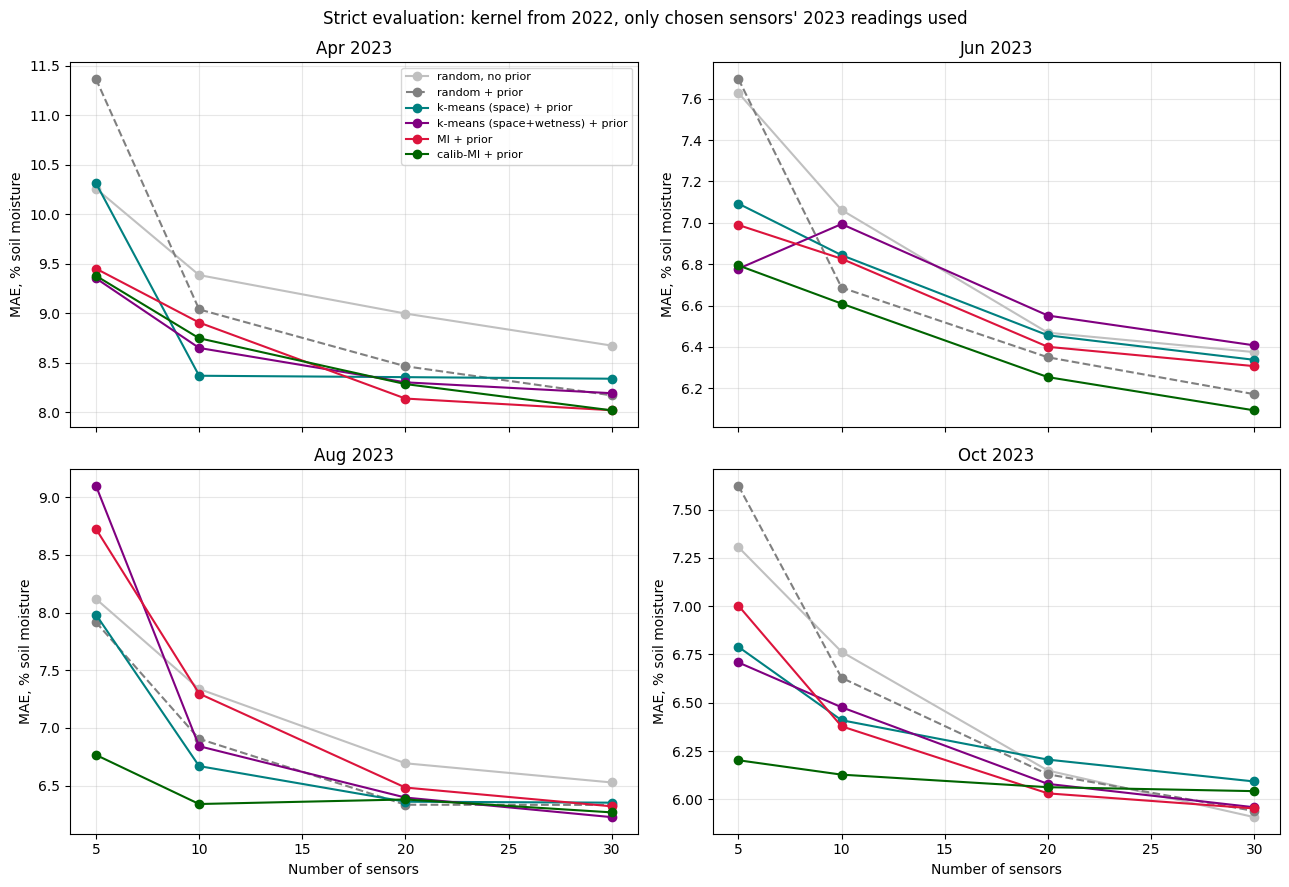

In [35]:
PAIRS16 = [("calib-MI + prior", "random, no prior"),
           ("calib-MI + prior", "random + prior"),
           ("calib-MI + prior", "k-means (space) + prior"),
           ("calib-MI + prior", "k-means (space+wetness) + prior"),
           ("calib-MI + prior", "MI + prior")]

for a_m, b_m in PAIRS16:
    print(f"--- {a_m}  vs  {b_m}")
    for n in COUNTS13:
        line = f"n={n:3d}  "
        total_w = 0
        total_n = 0
        for label in results16:
            ea = results16[label][n][a_m]
            eb = results16[label][n][b_m]
            w = 0
            for i in range(len(ea)):
                if ea[i] < eb[i]:
                    w = w + 1
            total_w = total_w + w
            total_n = total_n + len(ea)
            line = line + f"{label} {w}/{len(ea)} (p={sign_test_p(w, len(ea)):.3f})   "
        line = line + f"|  ALL {total_w}/{total_n} (p={sign_test_p(total_w, total_n):.4f})"
        print(line)
    print()

print("Average over the four months (strict evaluation):")
for n in COUNTS13:
    line = f"n={n:3d}  "
    for m in METHODS16:
        avg = 0.0
        for label in results16:
            avg = avg + np.mean(results16[label][n][m])
        line = line + f"{m} {avg / len(results16):.2f}   "
    print(line)

styles16 = {"random, no prior": ("silver", "-"), "random + prior": ("gray", "--"),
            "k-means (space) + prior": ("teal", "-"), "k-means (space+wetness) + prior": ("purple", "-"),
            "MI + prior": ("crimson", "-"), "calib-MI + prior": ("darkgreen", "-")}
fig, axes = plt.subplots(2, 2, figsize=(13, 9), sharex=True)
labels16 = list(results16)
for i in range(len(labels16)):
    ax = axes[i // 2][i % 2]
    for m in METHODS16:
        colour, ls = styles16[m]
        ax.plot(COUNTS13, [np.mean(results16[labels16[i]][n][m]) for n in COUNTS13],
                marker="o", color=colour, linestyle=ls, label=m)
    ax.set_title(labels16[i]); ax.grid(alpha=0.3); ax.set_ylabel("MAE, % soil moisture")
axes[1][0].set_xlabel("Number of sensors"); axes[1][1].set_xlabel("Number of sensors")
axes[0][0].legend(fontsize=8)
plt.suptitle("Strict evaluation: kernel from 2022, only chosen sensors' 2023 readings used")
plt.tight_layout(); plt.show()

In [36]:
# Save the June-2022 kernel for the app's Proof mode (so the app is leakage-free too)
kj = hist_kernels["Jun 2023"]["resid"]
kernel_json = {
    "source": "learned from SCAN June 2022 residuals (calibrated ERA5 prior), notebook section 16",
    "constant": float(kj.k1.k1.constant_value),
    "length_scale": float(kj.k1.k2.length_scale),
    "nu": float(kj.k1.k2.nu),
    "noise": float(kj.k2.noise_level),
    "resid_std": hist_kernels["Jun 2023"]["resid_std"],
}
with open("historical_kernel.json", "w") as f:
    json.dump(kernel_json, f, indent=2)
print(kernel_json)

# also save the strict results so every number in the app can be traced to this notebook
summary = {}
for n in COUNTS13:
    summary[str(n)] = {}
    for m in METHODS16:
        avg = 0.0
        for label in results16:
            avg = avg + np.mean(results16[label][n][m])
        summary[str(n)][m] = round(avg / len(results16), 2)
with open("experiment_results.json", "w") as f:
    json.dump({"source": "notebook section 16 (strict evaluation, 4 months x 50 runs)", "mae": summary}, f, indent=2)

from google.colab import files
files.download("historical_kernel.json")
files.download("experiment_results.json")

{'source': 'learned from SCAN June 2022 residuals (calibrated ERA5 prior), notebook section 16', 'constant': 0.35693550424296444, 'length_scale': 1.5885721592876918, 'nu': 1.5, 'noise': 0.5639644770107605, 'resid_std': 7.816608303820803}


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

## 9. Save

Hand this file to whoever is building the chatbot and the map view.

In [37]:
sensors.to_csv("soil_moisture_clean.csv", index=False)
print("saved", len(sensors), "stations")

# Uncomment to pull it onto your laptop:
from google.colab import files
files.download("soil_moisture_clean.csv")

saved 169 stations


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>